In [1]:
import numpy as np
import plyfile,copy
import pandas as pd
import tifffile as tiff

from scipy import io
import os
join = os.path.join
from PIL import Image
import matplotlib.pyplot as plt
import shutil
from scipy.signal import find_peaks
import open3d as o3d
from matplotlib.colors import Normalize
from scipy.interpolate import CubicSpline, Rbf
import SimpleITK as sitk

from geomdl import NURBS, utilities
from scipy.ndimage import convolve, gaussian_filter
import tigre
import tigre.algorithms as algs

import open3d as o3d

from scipy.interpolate import CubicSpline
from mpl_toolkits.mplot3d import Axes3D

import nibabel as nib

import random
import tqdm

import SimpleITK as sitk # 推荐用于医学图像处理
from skimage.morphology import skeletonize_3d
from skimage.measure import regionprops,label

import json

import nibabel as nib
import numpy as np
from scipy.ndimage import zoom

from scipy.ndimage import distance_transform_edt, binary_dilation

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## 基础函数

In [2]:
def show_slice(temp_slice):
    plt.figure(figsize=(6,6))
    plt.imshow(temp_slice,cmap = 'grey')
    plt.show()

def show_color_slice(perfusion_data, range=None, cmap='jet', title='Cerebral Blood Flow (CBF) Map'):
    """
    显示CBF彩色图
    
    参数:
    cbf_data -- 2D numpy数组，包含CBF值(ml/100ml/min)
    cbf_range -- 可选，颜色范围[min, max]
    cmap -- 颜色映射(默认'jet')，可选'viridis', 'plasma', 'hot'等
    title -- 图像标题
    """
    plt.figure(figsize=(6, 4))
    
    # 设置颜色范围
    if range is None:
        norm = Normalize(vmin=np.nanmin(perfusion_data), vmax=np.nanmax(perfusion_data))
    else:
        norm = Normalize(vmin=range[0], vmax=range[1])
    
    # 显示图像
    img = plt.imshow(perfusion_data, cmap=cmap, norm=norm)
    
    # 添加颜色条
    cbar = plt.colorbar(img, fraction=0.046, pad=0.04)
    # cbar.set_label('ml/100ml/min', rotation=270, labelpad=20)
    
    # 添加标题和调整布局
    plt.title(title)
    plt.axis('off')  # 关闭坐标轴
    
    # 显示网格线（可选）
    # plt.grid(True, color='gray', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def visualize_point_cloud(points_data):
    """
    可视化三维点云数据。

    Args:
        points_data (np.ndarray): 包含点x, y, z坐标的NumPy数组，形状为(N, 3)。
        filename (str, optional): 如果提供，将点云保存到文件中。
    """
    # 创建 Open3D 点云对象
    pcd = o3d.geometry.PointCloud()
    
    # 从 NumPy 数组赋值点云
    pcd.points = o3d.utility.Vector3dVector(points_data)
    
    # 可选：给点云上色，这里给所有点赋上统一的颜色
    pcd.paint_uniform_color([0.5, 0.5, 0.5])  # 灰色
    o3d.visualization.draw_geometries([pcd], 
                                      window_name="点云三维图",
                                      width=800,
                                      height=600,
                                      left=50,
                                      top=50)

def convert_point_cloud_to_ply(point_cloud,file_path):
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(point_cloud)
    o3d.io.write_point_cloud(file_path, pcd)

def trans_tif_rgb(tif_data):
    fen_mu = (np.max(tif_data)-np.min(tif_data))
    if(fen_mu==0):
        tif_data = np.zeros_like(tif_data, dtype=tif_data.dtype)
    else:
        tif_data = (tif_data-np.min(tif_data))/fen_mu
    tif_data = tif_data * 255
    tif_data = tif_data.astype(np.uint8)
    tif_data = np.stack([tif_data, tif_data, tif_data], axis=-1)
    # print(tif_data.shape)
    return Image.fromarray(tif_data)

def show_3d(ndarray):
    x,y,z = np.where(ndarray>0)
    points = np.vstack([x,y,z]).T
    visualize_point_cloud(points)


def plot_point_clouds_matplotlib(pcd_data,voxel_size=(512,512,512), save_path=None):
    """
    使用 Matplotlib 绘制多组点云，背景纯白，点为灰色。

    Args:
        point_clouds_ndarrays (list): 包含多个 (N, 3) 形状的 NumPy ndarray 的列表。
    """
    # 1. 创建 3D 绘图对象
    fig = plt.figure(figsize=(10, 10), facecolor='white') # 设置图表背景为白色
    ax = fig.add_subplot(111, projection='3d', facecolor='white') # 设置 3D 坐标系背景为白色

    # 2. 设置点的颜色和样式
    point_color = 'gray'
    marker_style = '.' # 使用点标记
    marker_size = 0.5 # 点的大小

    # 3. 遍历并绘制每组点云
    all_points = []
    if pcd_data.shape[0] > 0:
        # 提取 X, Y, Z 坐标
        x = pcd_data[:, 0]
        y = pcd_data[:, 1]
        z = pcd_data[:, 2]

        # 绘制点云
        ax.scatter(x, y, z, c=point_color, marker=marker_style, s=marker_size, alpha=1.0)
        all_points.append(pcd_data)

    # 4. 统一坐标轴范围
    # 这一步是为了确保所有点云都在视野内，且坐标轴范围一致。
    if all_points:
        ax.set_xlim(0, voxel_size[0])
        ax.set_ylim(0, voxel_size[1])
        ax.set_zlim(0, voxel_size[2])

    # 5. 【关键修改 A】：设置 3D Axes 的所有 pane 颜色为纯白色
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 1.0)) # (R, G, B, Alpha)
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 1.0))

    # 6. 【关键修改 B】：彻底隐藏坐标轴线、刻度、标签和网格线
    ax.set_axis_off() # 这是一个更全面的命令，用于移除所有轴线、刻度、标签

    # 此外，确保没有网格线 (虽然 set_axis_off 通常会处理)
    ax.grid(False) 
    
    # 【关键修改 C】：移除 3D pane 周围的黑色边缘线
    # Matplotlib 3D 默认会在 panes 之间画线，这部分需要手动清除
    # 通过设置 pane 颜色时使用透明度为 0 来隐藏其边缘
    ax.xaxis.line.set_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.line.set_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.line.set_color((1.0, 1.0, 1.0, 0.0))

    # 7. 【关键修改 D】：压缩子图和 Figure 边缘的空白
    # 注意：对于 3D 绘图，特别是旋转视角时，'tight' 可能不会完全消除所有空白。
    # 仍然建议使用 subplots_adjust 来最大化图表区域。
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

    if(save_path is not None):
        plt.savefig(save_path)
        plt.close(fig) #不显示图片
    else:
        plt.show()

In [5]:
def set_geo(DSD  =1250, 
            DSO = 750,
            nDetector = np.array([512,512]),
            dDetector = np.array([0.3, 0.3]), 
            nVoxel = np.array([248, 510, 636]),
            dVoxel = np.array([0.3, 0.3, 0.6]),
            geo_type='cone'):
    # Lets create a geometry object
    geo = tigre.geometry()
    # VARIABLE                                   DESCRIPTION                    UNITS
    # -------------------------------------------------------------------------------------
    # Distances
    geo.DSD = DSD  # Distance Source Detector      (mm)
    geo.DSO = DSO  # Distance Source Origin        (mm)
    # Detector parameters
    geo.nDetector = nDetector  # number of pixels              (px)
    geo.dDetector =dDetector  # size of each pixel            (mm)
    geo.sDetector = geo.nDetector * geo.dDetector  # total size of the detector    (mm)
    # Image parameters
    geo.nVoxel = nVoxel  # number of voxels              (vx)
    geo.dVoxel= dVoxel # size of each voxel            (mm)
    geo.sVoxel = geo.dVoxel * geo.nVoxel  # total size of the image       (mm)
    
    # Offsets
    geo.offOrigin = np.array([0, 0, 0])  # Offset of image from origin   (mm)
    # geo.offOrigin = geo.sVoxel /2 

    geo.offDetector = np.array([0, 0])  # Offset of Detector            (mm)
    # geo.offDetector = geo.sDetector / 2

    geo.accuracy = 0.5  # Variable to define accuracy of
    geo.COR = 0  # y direction displacement for
    geo.rotDetector = np.array([0, 0, 0])  # Rotation of the detector, by
    # geo.mode = "cone"  # Or 'parallel'. Geometry type.
    geo.mode = geo_type  # Or 'parallel'. Geometry type.
    return geo

### 数据读取

In [6]:
def read_ply(ply_path):
    pcd = o3d.io.read_point_cloud(ply_path)
    
    if not pcd.has_points():
        print(f"警告: 文件 {ply_path} 中没有读取到任何点。")
        return pcd, np.array([])
        
    # 将 Open3D 点云对象转换为 NumPy 数组
    point_cloud_np = np.asarray(pcd.points)
    return  point_cloud_np

## 获取ROI的投影数据

同时投影两个，只有ROI有值的图像和原图。之后将前者的投影作为mask去取后者的投影，方便快捷。计算有效射线的方法消耗的时间较长（512,512）的探测器大小、360个角度要计算半个小时

In [7]:
def get_rectangle_roi(roi_center,roi_size): #获得长方形区域的roi坐标
    box_min = (roi_center - roi_size / 2.0).astype(np.uint8)
    box_max = (roi_center + roi_size / 2.0).astype(np.uint8)
    x_coords, y_coords ,z_coords= np.mgrid[
        box_min[0] : box_max[0] + 1,
        box_min[1] : box_max[1] + 1,
        box_min[2] : box_max[2] + 1
    ]
    return np.vstack([x_coords.ravel(), y_coords.ravel() ,z_coords.ravel()])

def get_circle_roi(image_shape,roi_center,roi_radius): #获得圆形区域的roi坐标
    Nz, Nx, Ny = image_shape
    center_z, center_x, center_y = roi_center
    z_coords, x_coords, y_coords = np.mgrid[0:Nz, 0:Nx, 0:Ny]
    
    #计算每个体素到圆心在 XY 平面上的距离平方
    distance_sq = (x_coords - center_x)**2 + (y_coords - center_y)**2 + (z_coords - center_z)**2
    radius_sq = roi_radius**2
    mask = distance_sq <= radius_sq

    mask = mask.astype(np.uint8)
    z,x,y = np.where(mask>0)
    return np.vstack([z,x,y])

def get_roi_proj(image,geo,angles,valid_mesh):
    # 输入的mesh的shape要是(3,num_of_points)
    roi_image = np.zeros_like(image,np.float32)
    z_coords, x_coords ,y_coords = valid_mesh[0],valid_mesh[1],valid_mesh[2]
    roi_image[z_coords, x_coords, y_coords] = 1 #创建一个只有ROI区域有值的体膜
    roi_mask = tigre.Ax(roi_image,geo,angles)
    proj_data = tigre.Ax(image,geo,angles)
    roi_mask[roi_mask>0.01] = 1 #将其转换为mask
    roi_mask[roi_mask<=0.01] = 0
    roi_proj = proj_data * roi_mask #逐元素相乘提取数据
    return roi_proj,proj_data

In [114]:
# R
image_path = 'D:\desktop\stent\interior\data\\brain.tif'
image  = tiff.imread(image_path) # (383,512,512)

# ## 方形的roi: 
# roi_center = np.array([200, 200, 200])
# roi_size = np.array([100, 100, 100])
# mesh_grid = get_rectangle_roi(roi_center,roi_size)

## 圆形的roi
roi_center = np.array([200, 200, 200])
roi_radius = 50
point_mesh = get_circle_roi(image.shape,roi_center,50)

angles = np.linspace(0,2*np.pi,360)
geo = set_geo()

In [82]:
roi_proj,src_proj = get_roi_proj(image,geo,angles,point_mesh)

In [83]:
tiff.imwrite('d:/desktop/roi_image.tif',roi_proj)
tiff.imwrite('d:/desktop/src_proj.tif',src_proj)

In [42]:
## 尝试对roi数据进行重建
imgFDK = algs.fdk(roi_proj, geo, angles, filter='hamming') #有限角的重建结果

In [43]:
tiff.imwrite('D:/desktop/roi_recon.tif',imgFDK)

## 其他

### 看看dsa数据

In [2]:
dsa_proj = tiff.imread('D:\desktop\DSA\\4DRGS\data\case2\\DSA.tif')

In [4]:
dsa_img = dsa_proj[-1]

In [5]:
dsa_img.shape

(960, 1240)

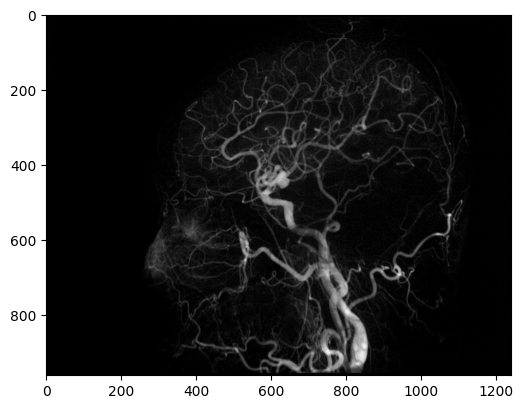

In [7]:
show_slice(dsa_img)

In [9]:
np.max(dsa_img)
np.min(dsa_img)

0.0

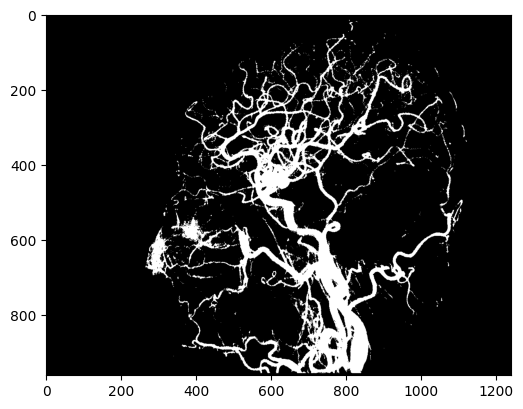

In [21]:
dsa_test = np.copy(dsa_img)
dsa_test[dsa_test < 0.1] = 0
dsa_test[dsa_test >= 0.1] = 1
show_slice(dsa_test)

In [24]:
tiff.imwrite('d:/desktop/dsa_test.tif',dsa_test)
tiff.imwrite('d:/desktop/dsa_img.tif',dsa_img)

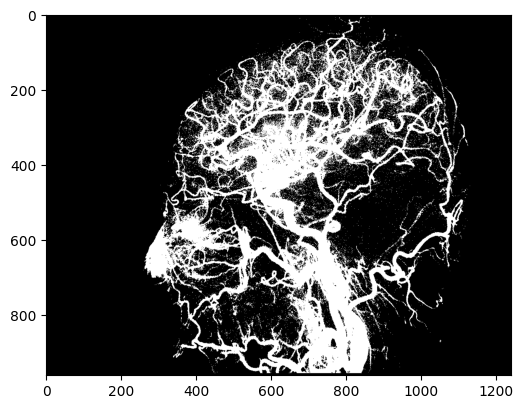

In [19]:
show_slice(dsa_test)

## TopCoW数据

### 数据的基础信息

In [145]:
# nib_dir = 'D:\desktop\TopBrain_Data_Release_Batch1_073025\imagesTr_topbrain_ct'
nib_dir = 'D:\desktop\stent\interior\data\TopBrain_Data_Release_Batch1_073025\imagesTr_topbrain_mr'
for i in os.listdir(nib_dir):
    nifti_img = nib.load(join(nib_dir,i))
    data = nifti_img.get_fdata()
    print(data.shape) # (width, height, depth)
    # continue
    header = nifti_img.header
    print(header['pixdim'][0:5])
    print(f"体素间距 (pixdim) (X, Y, Z, T...): {header['pixdim']}")
    print(f"图像维度 (dim) (X, Y, Z, T...): {header['dim']}")
    print(f"原始数据类型 (datatype): {header['datatype']}")
    print(f"物理单位 (xyzt_units): {header.get_xyzt_units()}")
    print(f"数据缩放斜率 (scl_slope): {header['scl_slope']}")
    print(f"数据缩放截距 (scl_inter): {header['scl_inter']}")
    print(f"Q-Form Code: {header['qform_code']}")
    print(f"S-Form Code: {header['sform_code']}")

    print('========')
    break

(508, 585, 189)
[1.        0.296875  0.296875  0.5999942 1.       ]
体素间距 (pixdim) (X, Y, Z, T...): [1.        0.296875  0.296875  0.5999942 1.        1.        1.
 1.       ]
图像维度 (dim) (X, Y, Z, T...): [  3 508 585 189   1   1   1   1]
原始数据类型 (datatype): 4
物理单位 (xyzt_units): ('mm', 'sec')
数据缩放斜率 (scl_slope): nan
数据缩放截距 (scl_inter): nan
Q-Form Code: 0
S-Form Code: 2


### 重采样以及预处理

In [93]:
## 检查原始图像的几何信息

nib_test_path = 'D:\desktop\stent\interior\save\mr\\nib\img'
for i in os.listdir(nib_test_path):
    nib_img = nib.load(join(nib_test_path,i))
    header = nib_img.header
    print(header['dim'][0:4],header['pixdim'][0:4],i)

[  3 510 636 248] [1.        0.296875  0.296875  0.5999942] topcow_mr_001_0000.nii.gz
[  3 510 636 248] [1.         0.29687497 0.296875   0.6000016 ] topcow_mr_002_0000.nii.gz
[  3 510 636 248] [1.         0.296875   0.296875   0.59999996] topcow_mr_003_0000.nii.gz
[  3 510 636 248] [1.         0.29687497 0.296875   0.600002  ] topcow_mr_004_0000.nii.gz
[  3 510 636 248] [1.        0.296875  0.296875  0.6000011] topcow_mr_005_0000.nii.gz
[  3 510 636 248] [1.        0.3515625 0.3515625 0.5000008] topcow_mr_006_0000.nii.gz
[  3 510 636 248] [1.        0.296875  0.296875  0.5999962] topcow_mr_007_0000.nii.gz
[  3 510 636 248] [1.        0.296875  0.296875  0.5999973] topcow_mr_008_0000.nii.gz
[  3 510 636 248] [1.        0.296875  0.296875  0.5999994] topcow_mr_010_0000.nii.gz
[  3 510 636 248] [1.        0.296875  0.296875  0.6000003] topcow_mr_011_0000.nii.gz
[  3 510 636 248] [1.         0.296875   0.296875   0.59999794] topcow_mr_012_0000.nii.gz
[  3 510 636 248] [1.        0.296875 

In [ ]:
## 检查原始图像的几何信息

nib_test_path = 'D:\desktop\TopBrain_Data_Release_Batches1n2_081425\imagesTr_topbrain_mr'
# nib_test_path = 'D:\desktop\TopBrain_Data_Release_Batches1n2_081425\imagesTr_topbrain_ct'
for i in os.listdir(nib_test_path):
    nib_img = nib.load(join(nib_test_path,i))
    header = nib_img.header
    print(header['dim'][0:4],header['pixdim'][0:4],i)

[  3 508 585 189] [1.        0.296875  0.296875  0.5999942] topcow_mr_001_0000.nii.gz
[  3 480 536 248] [1.         0.29687497 0.296875   0.6000016 ] topcow_mr_002_0000.nii.gz
[  3 510 577 179] [1.         0.296875   0.296875   0.59999996] topcow_mr_003_0000.nii.gz
[  3 500 607 200] [1.         0.29687497 0.296875   0.600002  ] topcow_mr_004_0000.nii.gz
[  3 470 566 196] [1.        0.296875  0.296875  0.6000011] topcow_mr_005_0000.nii.gz
[  3 429 507 139] [1.        0.3515625 0.3515625 0.5000008] topcow_mr_006_0000.nii.gz
[  3 490 561 200] [1.        0.296875  0.296875  0.5999962] topcow_mr_007_0000.nii.gz
[  3 485 592 181] [1.        0.296875  0.296875  0.5999973] topcow_mr_008_0000.nii.gz
[  3 459 556 194] [1.        0.296875  0.296875  0.5999994] topcow_mr_010_0000.nii.gz
[  3 470 581 153] [1.        0.296875  0.296875  0.6000003] topcow_mr_011_0000.nii.gz
[  3 469 611 174] [1.         0.296875   0.296875   0.59999794] topcow_mr_012_0000.nii.gz
[  3 470 597 186] [1.        0.296875 

In [13]:
def get_max_shape(nifti_dir):
    """
    获得目录下的平均体素大小
    """
    x_dim_max, y_dim_max, z_dim_max = 0,0,0
    for i in os.listdir(nifti_dir):
        nifti_img = nib.load(join(nifti_dir,i))
        img_data = nifti_img.get_fdata()
        x,y,z = img_data.shape[0],img_data.shape[1],img_data.shape[2]
        if(x_dim_max < x):
            x_dim_max = x
        if(y_dim_max < y):
            y_dim_max = y
        if(z_dim_max < z):
            z_dim_max = z
    
    return x_dim_max, y_dim_max, z_dim_max

def center_pad_ndarray(data: np.ndarray, target_shape: tuple, padding_value: float = 0.0) -> np.ndarray:

    # 填充ndarray到指定shape
    """
    将三维 NumPy 数组（图像）填充到指定的 target_shape，并确保原始图像居中。
    多余的区域用指定值（默认为 0）填充。

    参数:
        data (np.ndarray): 原始的三维图像数组 (H, W, D)。
        target_shape (tuple): 目标的三维 shape (H_target, W_target, D_target)。
        padding_value (float): 用于填充的常量值（默认为 0.0）。

    返回:
        np.ndarray: 填充后的数组，维度为 target_shape。
    """
    if data.ndim != 3 or len(target_shape) != 3:
        raise ValueError("输入数据必须是 3 维，目标 shape 也必须是 3 维元组。")

    padding_width = []
    
    # 遍历三个维度 (H, W, D)
    for i in range(3):
        current_size = data.shape[i]
        target_size = target_shape[i]
        
        if current_size > target_size:
            # 如果原始尺寸大于目标尺寸，则裁剪而不是填充
            raise ValueError(
                f"维度 {i} 的原始尺寸 ({current_size}) 大于目标尺寸 ({target_size})。"
            )

        # 计算总填充量
        total_pad = target_size - current_size
        
        # 计算前部和后部填充量 (确保能处理奇数填充量)
        pad_before = total_pad // 2
        pad_after = total_pad - pad_before
        
        padding_width.append((pad_before, pad_after))

    # 使用 np.pad 进行填充
    padded_data = np.pad(
        data, 
        pad_width=padding_width, 
        mode='constant', 
        constant_values=padding_value
    )
    
    return padded_data

def center_pad_nifti(nifti_img, new_shape,fill_value=0):
    ## 就算只是单纯将的nib图像放在新shape的中心，也需要对其affine进行调整
    data = nifti_img.get_fdata()
    affine = nifti_img.affine.copy()

    old_shape = np.array(data.shape)
    new_shape = np.array(new_shape)

    # 计算每个方向需要 pad 的数量
    pad_total = new_shape - old_shape
    pad_before = pad_total // 2
    pad_after = pad_total - pad_before
    pad_width = list(zip(pad_before, pad_after))

    # 填充数据
    padded_data = np.pad(data, pad_width, mode='constant', constant_values=fill_value)

    # 计算 affine 的平移修正
    offset = np.array(pad_before)
    new_affine = affine.copy()
    new_affine[:3, 3] -= affine[:3, :3] @ offset

    # 创建新的 NIfTI 对象
    new_img = nib.Nifti1Image(padded_data, new_affine, nifti_img.header)

    return new_img

def resample_nifti(nifti_img: nib.Nifti1Image, target_spacing: tuple, order: int = 1):
    """
    将 Nifti1Image 重采样到指定体素大小。
    
    参数：
        nifti_img : nib.Nifti1Image
            原始 NIfTI 图像对象
        target_spacing : tuple(float, float, float)
            目标体素大小 (x, y, z)，单位 mm
        order : int
            插值阶数，0=最近邻，1=线性，3=三次样条

    返回：
        new_img : nib.Nifti1Image
            重采样后的 NIfTI 图像对象
    """

    # 1️⃣ 获取原始数据和仿射矩阵
    data = nifti_img.get_fdata()
    affine = nifti_img.affine.copy()

    # 2️⃣ 从 affine 提取当前 spacing
    original_spacing = np.abs(affine.diagonal()[:3])

    # 3️⃣ 计算缩放比例
    zoom_factors = original_spacing / np.array(target_spacing)

    # 4️⃣ 重采样数据（插值）
    resampled_data = zoom(data, zoom=zoom_factors, order=order)

    # 5️⃣ 更新仿射矩阵
    new_affine = affine.copy()
    scale_ratio = np.array(target_spacing) / original_spacing
    new_affine[:3, :3] = affine[:3, :3] * scale_ratio

    # 6️⃣ 创建新的 Nifti1Image
    new_img = nib.Nifti1Image(resampled_data, new_affine, nifti_img.header)

    # 同步 header 中的像素间距信息
    new_img.header.set_zooms(target_spacing)

    return new_img

def convert_nifti_to_tif(nifti_img):
    canonical_img = nib.as_closest_canonical(nifti_img)
    data = canonical_img.get_fdata()
    data = np.transpose(data.astype(np.float32), (2, 0, 1))  # 转换为 (z, x, y) 顺序
    return data

def work_with_label(nifti_dir,label_dir,save_dir):
    ## 将图像和label一起转换
    nib_img_save_path = join(save_dir,'nib/img')
    nib_label_save_path = join(save_dir,'nib/label')
    tif_img_save_path = join(save_dir,'tif/img')
    tif_label_save_path = join(save_dir,'tif/label')
    os.makedirs(nib_img_save_path, exist_ok=True)
    os.makedirs(nib_label_save_path, exist_ok=True)
    os.makedirs(tif_img_save_path, exist_ok=True)
    os.makedirs(tif_label_save_path, exist_ok=True)

    img_list = sorted(os.listdir(nifti_dir))
    label_list = sorted(os.listdir(label_dir))

    # x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = get_ave_voxel_size_and_shape(nifti_dir)
    x_dim_max, y_dim_max, z_dim_max = get_max_shape(nifti_dir)
    print( x_dim_max, y_dim_max, z_dim_max)

    # print(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max)

    for index,i in enumerate(label_list):
        nifti_img = nib.load(join(nifti_dir,img_list[index]))
        nifti_label = nib.load(join(label_dir,label_list[index]))
        """
        重采样的时候，order千万不能为3，不然会出现很奇怪的值。就填order=1也就是线性插值
        """
        # resampled_img = resample_nifti(nifti_img, target_spacing=(x_voxel_size,y_voxel_size,z_voxel_size), order=1)
        # resampled_label = resample_nifti(nifti_label, target_spacing=(x_voxel_size,y_voxel_size,z_voxel_size), order=1)
        resampled_img = copy.copy(nifti_img)
        resampled_label = copy.copy(nifti_label)
        
        # print(np.min(resampled_img))
        resampled_img = center_pad_nifti(resampled_img, (x_dim_max, y_dim_max, z_dim_max),fill_value=np.min(resampled_img.get_fdata()))
        resampled_label = center_pad_nifti(resampled_label, (x_dim_max, y_dim_max, z_dim_max),fill_value=0)

        nib.save(resampled_img, join(nib_img_save_path,i))
        nib.save(resampled_label, join(nib_label_save_path,i))
        tiff.imwrite(join(tif_img_save_path,i.split('.nii.gz')[0]+'.tif'), convert_nifti_to_tif(resampled_img))
        tiff.imwrite(join(tif_label_save_path,i.split('.nii.gz')[0]+'.tif'), convert_nifti_to_tif(resampled_label))
        print(i)
        # break
    
    # return x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max
    return -1,-1,-1,x_dim_max, y_dim_max, z_dim_max
    # print(x_voxel_size,y_voxel_size,z_voxel_size)

def write_para(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max,save_dir = './'):
    x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = int(x_voxel_size),int(y_voxel_size),int(z_voxel_size),int(x_dim_max),int(y_dim_max),int(z_dim_max)

    # 1. 组织数据为 Python 字典
    data_to_save = {
        "x_voxel_size": x_voxel_size,
        "y_voxel_size": y_voxel_size,
        "z_voxel_size": z_voxel_size,
        "x_dim_max": x_dim_max,
        "y_dim_max": y_dim_max,
        "z_dim_max": z_dim_max
    }
    file_path = join(save_dir,"voxel_and_dim_info.json")

    with open(file_path, 'w', encoding='utf-8') as f:
        # 使用 json.dump() 写入文件
        # indent=4 使文件格式化输出，易于阅读
        json.dump(data_to_save, f, ensure_ascii=False, indent=4)

In [122]:
# nib.load('D:\desktop\TopBrain_Data_Release_Batches1n2_081425\imagesTr_topbrain_mr\\topcow_mr_001_0000.nii.gz').get_fdata().shape

In [14]:
# nifti_dir = '/data1/liuyang/stent/interior/topbrain/imagesTr_topbrain_mr'
# label_dir = '/data1/liuyang/stent/interior/topbrain/labelsTr_topbrain_mr'
# save_dir = 'D:\desktop\TopBrain_Data_Release_Batches1n2_081425\mr'

# for i in os.listdir(nifti_dir):
#     os.rename(join(nifti_dir,i),join(nifti_dir,i.split('topcow_')[-1]))
# for i in os.listdir(label_dir):
#     os.rename(join(label_dir,i),join(label_dir,i.split('topcow_')[-1]))

nifti_dir = '/data1/liuyang/stent/interior/topbrain/imagesTr_topbrain_mr'
label_dir = '/data1/liuyang/stent/interior/topbrain/labelsTr_topbrain_mr'
save_dir = '/data1/liuyang/stent/interior/data'
x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = work_with_label(nifti_dir,label_dir, save_dir)
print(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max)
write_para(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max,save_dir)

515 636 248
mr_001.nii.gz
mr_002.nii.gz
mr_003.nii.gz
mr_004.nii.gz
mr_005.nii.gz
mr_006.nii.gz
mr_007.nii.gz
mr_008.nii.gz
mr_010.nii.gz
mr_011.nii.gz
mr_012.nii.gz
mr_013.nii.gz
mr_014.nii.gz
mr_015.nii.gz
mr_016.nii.gz
mr_017.nii.gz
mr_018.nii.gz
mr_020.nii.gz
mr_021.nii.gz
mr_022.nii.gz
mr_023.nii.gz
mr_024.nii.gz
mr_025.nii.gz
mr_026.nii.gz
mr_027.nii.gz
-1 -1 -1 515 636 248


### 获得label的投影

In [ ]:
# ## 对label投影
# label_dir = 'D:\desktop\stent\interior\save\mr\\tif\label'
# proj_save_dir = 'D:\desktop\stent\interior\save\\mr\label_proj'
# os.makedirs(proj_save_dir, exist_ok=True)
# for i in os.listdir(label_dir):
#     label = tiff.imread(join(label_dir,i))
#     label[label > 0.5] = 1
#     label[label <= 0.5] = 0
#     label.astype(np.uint8).astype(np.float32)
#     geo = set_geo()
#     angles = np.linspace(0,2*np.pi,360)
#     label_proj = tigre.Ax(label,geo,angles)
#     tiff.imwrite(join(proj_save_dir,i),label_proj)
#     print(i)
#     # break

In [ ]:
# # label = tiff.imread('D:\desktop\stent\interior\save\mr\\tif\label\\topcow_mr_010_0000.tif')
# label = tiff.imread('D:\desktop\stent\interior\save\mr\\tif\label\\topcow_mr_010_0000.tif')
# show_3d(label)

### 检查数据的类别

In [15]:
BRAIN_VESSEL_LABELS_CT = {
    # 格式: IDX: {"LABEL": 标签缩写, "FULL_NAME_EN": 英文全称, "FULL_NAME_ZH": 中文全称}
    0:  {"LABEL": "Clear Label", "FULL_NAME_EN": "N/A", "FULL_NAME_ZH": "清除标签 / 背景", "NOTE": "未标记的区域"},
    1:  {"LABEL": "BA", "FULL_NAME_EN": "Basilar Artery", "FULL_NAME_ZH": "基底动脉", "NOTE": "脑干前的中线大动脉"},
    2:  {"LABEL": "R-P1P2", "FULL_NAME_EN": "Right Posterior Cerebral Artery, segments P1 & P2", "FULL_NAME_ZH": "右侧大脑后动脉 P1 和 P2 段", "NOTE": "脑后方的动脉"},
    3:  {"LABEL": "L-P1P2", "FULL_NAME_EN": "Left Posterior Cerebral Artery, segments P1 & P2", "FULL_NAME_ZH": "左侧大脑后动脉 P1 和 P2 段", "NOTE": "脑后方的动脉"},
    4:  {"LABEL": "R-ICA", "FULL_NAME_EN": "Right Internal Carotid Artery", "FULL_NAME_ZH": "右侧颈内动脉", "NOTE": "供应大脑的主要动脉之一"},
    5:  {"LABEL": "R-M1", "FULL_NAME_EN": "Right Middle Cerebral Artery, segment M1", "FULL_NAME_ZH": "右侧大脑中动脉 M1 段", "NOTE": "M1 段是主干，位于外侧裂内"},
    6:  {"LABEL": "L-ICA", "FULL_NAME_EN": "Left Internal Carotid Artery", "FULL_NAME_ZH": "左侧颈内动脉", "NOTE": "供应大脑的主要动脉之一"},
    7:  {"LABEL": "L-M1", "FULL_NAME_EN": "Left Middle Cerebral Artery, segment M1", "FULL_NAME_ZH": "左侧大脑中动脉 M1 段", "NOTE": ""},
    8:  {"LABEL": "R-Pcom", "FULL_NAME_EN": "Right Posterior Communicating Artery", "FULL_NAME_ZH": "右侧后交通动脉", "NOTE": "连接大脑中动脉系统和后动脉系统"},
    9:  {"LABEL": "L-Pcom", "FULL_NAME_EN": "Left Posterior Communicating Artery", "FULL_NAME_ZH": "左侧后交通动脉", "NOTE": ""},
    10: {"LABEL": "Acom", "FULL_NAME_EN": "Anterior Communicating Artery", "FULL_NAME_ZH": "前交通动脉", "NOTE": "连接两侧大脑前动脉 (A1 段)"},
    11: {"LABEL": "R-A1A2", "FULL_NAME_EN": "Right Anterior Cerebral Artery, segments A1 & A2", "FULL_NAME_ZH": "右侧大脑前动脉 A1 和 A2 段", "NOTE": ""},
    12: {"LABEL": "L-A1A2", "FULL_NAME_EN": "Left Anterior Cerebral Artery, segments A1 & A2", "FULL_NAME_ZH": "左侧大脑前动脉 A1 和 A2 段", "NOTE": ""},
    13: {"LABEL": "R-A3", "FULL_NAME_EN": "Right Anterior Cerebral Artery, segment A3", "FULL_NAME_ZH": "右侧大脑前动脉 A3 段", "NOTE": ""},
    14: {"LABEL": "L-A3", "FULL_NAME_EN": "Left Anterior Cerebral Artery, segment A3", "FULL_NAME_ZH": "左侧大脑前动脉 A3 段", "NOTE": ""},
    15: {"LABEL": "3rd-A2", "FULL_NAME_EN": "3rd Anterior Cerebral Artery, segment A2 (Variant)", "FULL_NAME_ZH": "第三大脑前动脉 A2 段 (变异)", "NOTE": "一种罕见的解剖变异"},
    16: {"LABEL": "3rd-A3", "FULL_NAME_EN": "3rd Anterior Cerebral Artery, segment A3 (Variant)", "FULL_NAME_ZH": "第三大脑前动脉 A3 段 (变异)", "NOTE": ""},
    17: {"LABEL": "R-M2", "FULL_NAME_EN": "Right Middle Cerebral Artery, segment M2", "FULL_NAME_ZH": "右侧大脑中动脉 M2 段", "NOTE": "M1 分支后的皮质分支"},
    18: {"LABEL": "R-M3", "FULL_NAME_EN": "Right Middle Cerebral Artery, segment M3", "FULL_NAME_ZH": "右侧大脑中动脉 M3 段", "NOTE": "更远端的皮质分支"},
    19: {"LABEL": "L-M2", "FULL_NAME_EN": "Left Middle Cerebral Artery, segment M2", "FULL_NAME_ZH": "左侧大脑中动脉 M2 段", "NOTE": ""},
    20: {"LABEL": "L-M3", "FULL_NAME_EN": "Left Middle Cerebral Artery, segment M3", "FULL_NAME_ZH": "左侧大脑中动脉 M3 段", "NOTE": ""},
    21: {"LABEL": "R-P3P4", "FULL_NAME_EN": "Right Posterior Cerebral Artery, segments P3 & P4", "FULL_NAME_ZH": "右侧大脑后动脉 P3 和 P4 段", "NOTE": ""},
    22: {"LABEL": "L-P3P4", "FULL_NAME_EN": "Left Posterior Cerebral Artery, segments P3 & P4", "FULL_NAME_ZH": "左侧大脑后动脉 P3 和 P4 段", "NOTE": ""},
    23: {"LABEL": "R-VA", "FULL_NAME_EN": "Right Vertebral Artery", "FULL_NAME_ZH": "右侧椎动脉", "NOTE": "向上汇合形成基底动脉 (BA)"},
    24: {"LABEL": "L-VA", "FULL_NAME_EN": "Left Vertebral Artery", "FULL_NAME_ZH": "左侧椎动脉", "NOTE": ""},
    25: {"LABEL": "R-SCA", "FULL_NAME_EN": "Right Superior Cerebellar Artery", "FULL_NAME_ZH": "右侧小脑上动脉", "NOTE": ""},
    26: {"LABEL": "L-SCA", "FULL_NAME_EN": "Left Superior Cerebellar Artery", "FULL_NAME_ZH": "左侧小脑上动脉", "NOTE": ""},
    27: {"LABEL": "R-AICA", "FULL_NAME_EN": "Right Anterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "右侧小脑前下动脉", "NOTE": ""},
    28: {"LABEL": "L-AICA", "FULL_NAME_EN": "Left Anterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "左侧小脑前下动脉", "NOTE": ""},
    29: {"LABEL": "R-PICA", "FULL_NAME_EN": "Right Posterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "右侧小脑后下动脉", "NOTE": ""},
    30: {"LABEL": "L-PICA", "FULL_NAME_EN": "Left Posterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "左侧小脑后下动脉", "NOTE": ""},
    31: {"LABEL": "R-AChA", "FULL_NAME_EN": "Right Anterior Choroidal Artery", "FULL_NAME_ZH": "右侧脉络膜前动脉", "NOTE": "颈内动脉的分支"},
    32: {"LABEL": "L-AChA", "FULL_NAME_EN": "Left Anterior Choroidal Artery", "FULL_NAME_ZH": "左侧脉络膜前动脉", "NOTE": ""},
    33: {"LABEL": "R-OA", "FULL_NAME_EN": "Right Ophthalmic Artery", "FULL_NAME_ZH": "右侧眼动脉", "NOTE": ""},
    34: {"LABEL": "L-OA", "FULL_NAME_EN": "Left Ophthalmic Artery", "FULL_NAME_ZH": "左侧眼动脉", "NOTE": ""},
    35: {"LABEL": "VoG", "FULL_NAME_EN": "Vein of Galen", "FULL_NAME_ZH": "大脑大静脉（盖伦静脉）", "NOTE": "重要的脑深静脉"},
    36: {"LABEL": "StS", "FULL_NAME_EN": "Straight Sinus", "FULL_NAME_ZH": "直窦", "NOTE": "重要的硬脑膜静脉窦"},
    37: {"LABEL": "ICVs", "FULL_NAME_EN": "Internal Cerebral Veins", "FULL_NAME_ZH": "大脑内静脉", "NOTE": "汇入大脑大静脉 (VoG)"},
    38: {"LABEL": "R-BVR", "FULL_NAME_EN": "Right Brain Vessel Region", "FULL_NAME_ZH": "右脑血管区域", "NOTE": "可能是指右侧大脑的其它未特定命名的小血管集合"},
    39: {"LABEL": "L-BVR", "FULL_NAME_EN": "Left Brain Vessel Region", "FULL_NAME_ZH": "左脑血管区域", "NOTE": "可能是指左侧大脑的其它未特定命名的小血管集合"},
    40: {"LABEL": "SSS", "FULL_NAME_EN": "Superior Sagittal Sinus", "FULL_NAME_ZH": "上矢状窦", "NOTE": "重要的硬脑膜静脉窦"},
}

BRAIN_VESSEL_LABELS_MR = {
    # 颅内动脉及静脉窦 (IDX 0-34, 43个)
    0:  {"LABEL": "Clear Label", "FULL_NAME_EN": "N/A", "FULL_NAME_ZH": "清除标签 / 背景", "TYPE": "Background"},
    1:  {"LABEL": "BA", "FULL_NAME_EN": "Basilar Artery", "FULL_NAME_ZH": "基底动脉", "TYPE": "Artery (Posterior)"},
    2:  {"LABEL": "R-P1P2", "FULL_NAME_EN": "Right Posterior Cerebral Artery, segments P1 & P2", "FULL_NAME_ZH": "右侧大脑后动脉 P1 和 P2 段", "TYPE": "Artery (Posterior)"},
    3:  {"LABEL": "L-P1P2", "FULL_NAME_EN": "Left Posterior Cerebral Artery, segments P1 & P2", "FULL_NAME_ZH": "左侧大脑后动脉 P1 和 P2 段", "TYPE": "Artery (Posterior)"},
    4:  {"LABEL": "R-ICA", "FULL_NAME_EN": "Right Internal Carotid Artery", "FULL_NAME_ZH": "右侧颈内动脉", "TYPE": "Artery (Anterior)"},
    5:  {"LABEL": "R-M1", "FULL_NAME_EN": "Right Middle Cerebral Artery, segment M1", "FULL_NAME_ZH": "右侧大脑中动脉 M1 段", "TYPE": "Artery (Anterior)"},
    6:  {"LABEL": "L-ICA", "FULL_NAME_EN": "Left Internal Carotid Artery", "FULL_NAME_ZH": "左侧颈内动脉", "TYPE": "Artery (Anterior)"},
    7:  {"LABEL": "L-M1", "FULL_NAME_EN": "Left Middle Cerebral Artery, segment M1", "FULL_NAME_ZH": "左侧大脑中动脉 M1 段", "TYPE": "Artery (Anterior)"},
    8:  {"LABEL": "R-Pcom", "FULL_NAME_EN": "Right Posterior Communicating Artery", "FULL_NAME_ZH": "右侧后交通动脉", "TYPE": "Artery (Communicating)"},
    9:  {"LABEL": "L-Pcom", "FULL_NAME_EN": "Left Posterior Communicating Artery", "FULL_NAME_ZH": "左侧后交通动脉", "TYPE": "Artery (Communicating)"},
    10: {"LABEL": "Acom", "FULL_NAME_EN": "Anterior Communicating Artery", "FULL_NAME_ZH": "前交通动脉", "TYPE": "Artery (Communicating)"},
    11: {"LABEL": "R-A1A2", "FULL_NAME_EN": "Right Anterior Cerebral Artery, segments A1 & A2", "FULL_NAME_ZH": "右侧大脑前动脉 A1 和 A2 段", "TYPE": "Artery (Anterior)"},
    12: {"LABEL": "L-A1A2", "FULL_NAME_EN": "Left Anterior Cerebral Artery, segments A1 & A2", "FULL_NAME_ZH": "左侧大脑前动脉 A1 和 A2 段", "TYPE": "Artery (Anterior)"},
    13: {"LABEL": "R-A3", "FULL_NAME_EN": "Right Anterior Cerebral Artery, segment A3", "FULL_NAME_ZH": "右侧大脑前动脉 A3 段", "TYPE": "Artery (Anterior)"},
    14: {"LABEL": "L-A3", "FULL_NAME_EN": "Left Anterior Cerebral Artery, segment A3", "FULL_NAME_ZH": "左侧大脑前动脉 A3 段", "TYPE": "Artery (Anterior)"},
    15: {"LABEL": "3rd-A2", "FULL_NAME_EN": "3rd Anterior Cerebral Artery, segment A2 (Variant)", "FULL_NAME_ZH": "第三大脑前动脉 A2 段 (变异)", "TYPE": "Artery (Variant)"},
    16: {"LABEL": "3rd-A3", "FULL_NAME_EN": "3rd Anterior Cerebral Artery, segment A3 (Variant)", "FULL_NAME_ZH": "第三大脑前动脉 A3 段 (变异)", "TYPE": "Artery (Variant)"},
    17: {"LABEL": "R-M2", "FULL_NAME_EN": "Right Middle Cerebral Artery, segment M2", "FULL_NAME_ZH": "右侧大脑中动脉 M2 段", "TYPE": "Artery (Anterior)"},
    18: {"LABEL": "R-M3", "FULL_NAME_EN": "Right Middle Cerebral Artery, segment M3", "FULL_NAME_ZH": "右侧大脑中动脉 M3 段", "TYPE": "Artery (Anterior)"},
    19: {"LABEL": "L-M2", "FULL_NAME_EN": "Left Middle Cerebral Artery, segment M2", "FULL_NAME_ZH": "左侧大脑中动脉 M2 段", "TYPE": "Artery (Anterior)"},
    20: {"LABEL": "L-M3", "FULL_NAME_EN": "Left Middle Cerebral Artery, segment M3", "FULL_NAME_ZH": "左侧大脑中动脉 M3 段", "TYPE": "Artery (Anterior)"},
    21: {"LABEL": "R-P3P4", "FULL_NAME_EN": "Right Posterior Cerebral Artery, segments P3 & P4", "FULL_NAME_ZH": "右侧大脑后动脉 P3 和 P4 段", "TYPE": "Artery (Posterior)"},
    22: {"LABEL": "L-P3P4", "FULL_NAME_EN": "Left Posterior Cerebral Artery, segments P3 & P4", "FULL_NAME_ZH": "左侧大脑后动脉 P3 和 P4 段", "TYPE": "Artery (Posterior)"},
    23: {"LABEL": "R-VA", "FULL_NAME_EN": "Right Vertebral Artery", "FULL_NAME_ZH": "右侧椎动脉", "TYPE": "Artery (Posterior)"},
    24: {"LABEL": "L-VA", "FULL_NAME_EN": "Left Vertebral Artery", "FULL_NAME_ZH": "左侧椎动脉", "TYPE": "Artery (Posterior)"},
    25: {"LABEL": "R-SCA", "FULL_NAME_EN": "Right Superior Cerebellar Artery", "FULL_NAME_ZH": "右侧小脑上动脉", "TYPE": "Artery (Cerebellar)"},
    26: {"LABEL": "L-SCA", "FULL_NAME_EN": "Left Superior Cerebellar Artery", "FULL_NAME_ZH": "左侧小脑上动脉", "TYPE": "Artery (Cerebellar)"},
    27: {"LABEL": "R-AICA", "FULL_NAME_EN": "Right Anterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "右侧小脑前下动脉", "TYPE": "Artery (Cerebellar)"},
    28: {"LABEL": "L-AICA", "FULL_NAME_EN": "Left Anterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "左侧小脑前下动脉", "TYPE": "Artery (Cerebellar)"},
    29: {"LABEL": "R-PICA", "FULL_NAME_EN": "Right Posterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "右侧小脑后下动脉", "TYPE": "Artery (Cerebellar)"},
    30: {"LABEL": "L-PICA", "FULL_NAME_EN": "Left Posterior Inferior Cerebellar Artery", "FULL_NAME_ZH": "左侧小脑后下动脉", "TYPE": "Artery (Cerebellar)"},
    31: {"LABEL": "R-AChA", "FULL_NAME_EN": "Right Anterior Choroidal Artery", "FULL_NAME_ZH": "右侧脉络膜前动脉", "TYPE": "Artery (Deep)"},
    32: {"LABEL": "L-AChA", "FULL_NAME_EN": "Left Anterior Choroidal Artery", "FULL_NAME_ZH": "左侧脉络膜前动脉", "TYPE": "Artery (Deep)"},
    33: {"LABEL": "R-OA", "FULL_NAME_EN": "Right Ophthalmic Artery", "FULL_NAME_ZH": "右侧眼动脉", "TYPE": "Artery (Intracranial)"},
    34: {"LABEL": "L-OA", "FULL_NAME_EN": "Left Ophthalmic Artery", "FULL_NAME_ZH": "左侧眼动脉", "TYPE": "Artery (Intracranial)"},
    
    # 颅外血管及深静脉（新增或调整）
    35: {"LABEL": "R-ECA", "FULL_NAME_EN": "Right External Carotid Artery", "FULL_NAME_ZH": "右侧颈外动脉", "TYPE": "Artery (Extracranial)"},
    36: {"LABEL": "L-ECA", "FULL_NAME_EN": "Left External Carotid Artery", "FULL_NAME_ZH": "左侧颈外动脉", "TYPE": "Artery (Extracranial)"},
    37: {"LABEL": "R-STA", "FULL_NAME_EN": "Right Superficial Temporal Artery", "FULL_NAME_ZH": "右侧颞浅动脉", "TYPE": "Artery (Extracranial)"},
    38: {"LABEL": "L-STA", "FULL_NAME_EN": "Left Superficial Temporal Artery", "FULL_NAME_ZH": "左侧颞浅动脉", "TYPE": "Artery (Extracranial)"},
    39: {"LABEL": "R-MaxA", "FULL_NAME_EN": "Right Maxillary Artery", "FULL_NAME_ZH": "右侧上颌动脉", "TYPE": "Artery (Extracranial)"},
    40: {"LABEL": "L-MaxA", "FULL_NAME_EN": "Left Maxillary Artery", "FULL_NAME_ZH": "左侧上颌动脉", "TYPE": "Artery (Extracranial)"},
    41: {"LABEL": "R-MMA", "FULL_NAME_EN": "Right Middle Meningeal Artery", "FULL_NAME_ZH": "右侧脑膜中动脉", "TYPE": "Artery (Extracranial)"},
    42: {"LABEL": "L-MMA", "FULL_NAME_EN": "Left Middle Meningeal Artery", "FULL_NAME_ZH": "左侧脑膜中动脉", "TYPE": "Artery (Extracranial)"},
    # 注意：如果您的原始数据中包含 VoG (35), StS (36), SSS (40) 等静脉标签，
    # 但新的列表用动脉覆盖了这些 IDX，那么请以新的列表为准。
    # 这里我们假设您已经更新了标签文件，用新的动脉标签替换了旧的静脉标签。
}

# # 创建逆向查找字典：标签名称 -> 索引
# LABEL_TO_IDX = {data['LABEL']: idx for idx, data in BRAIN_VESSEL_LABELS_CT.items()}

# # 只取出动脉的部分，取出6个静脉的标签
# non_artery = ['VoG','ICVs','StS','R-BVR','L-BVR','SSS']
# target_indices = []
# for label in non_artery:
#     idx = LABEL_TO_IDX.get(label)
#     if idx is not None:
#         target_indices.append(idx)
#     else:
#         print(f"警告：标签 '{label}' 未在字典中找到。")

In [ ]:


# def calculate_voxel_proportions(segmentation_map, label_dictionary):
#     """
#     计算分割掩码中每个标签占总有效体素（非零值）的百分比。

#     参数:
#     - segmentation_map (np.ndarray): 包含整数索引（IDX）的分割图。
#     - label_dictionary (dict): IDX 到标签信息的映射字典。

#     返回:
#     - pd.DataFrame: 包含 IDX、标签名称、计数和占比的结果表。
#     """
#     # 统计所有有效体素（非零值）
#     total_effective_voxels = np.sum(segmentation_map != 0)

#     if total_effective_voxels == 0:
#         print("错误：分割图中没有有效的（非零）体素。无法计算占比。")
#         return pd.DataFrame()

#     # 统计每个唯一值的计数
#     unique_indices, counts = np.unique(segmentation_map, return_counts=True)
    
#     # 转换为 DataFrame
#     results = pd.DataFrame({'IDX': unique_indices, 'Count': counts})
    
#     # 过滤掉背景 (IDX = 0)
#     results = results[results['IDX'] != 0].copy()
    
#     # 计算占比
#     results['Proportion (%)'] = (results['Count'] / total_effective_voxels) * 100
    
#     # 增加标签名称
#     def get_label_info(idx):
#         return label_dictionary.get(idx, {"LABEL": f"Unknown_{idx}", "FULL_NAME_ZH": f"未知结构 {idx}"})

#     results['Label'] = results['IDX'].apply(lambda x: get_label_info(x)['LABEL'])
#     results['Full Name (ZH)'] = results['IDX'].apply(lambda x: get_label_info(x)['FULL_NAME_ZH'])
    
#     # 整理并按占比降序排序
#     results = results[['IDX', 'Label', 'Full Name (ZH)', 'Count', 'Proportion (%)']]
#     results = results.sort_values(by='Proportion (%)', ascending=False)
    
#     return results, total_effective_voxels

In [17]:
## 查看原始数据的label都有哪些值
# nib_src = nib.load('D:\desktop\TopBrain_Data_Release_Batch1_073025\labelsTr_topbrain_ct\\topcow_ct_001.nii.gz')
# nib_data = nib_src.get_fdata()
# np.unique(nib_data, return_counts=True) #原始的nib文件确实只包括了0-40的标签

## 查看处理之后的label都有哪些值
label_path = '/data1/liuyang/stent/interior/data/tif/label/mr_001.tif'
label = tiff.imread(label_path)
label_int = np.round(label).astype(np.uint8)

np.unique(label_int, return_counts=True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8, 11, 12, 13, 14, 17, 18, 19, 20,
        21, 22, 23, 24, 25, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38,
        39, 40, 41, 42], dtype=uint8),
 array([80940066,     8407,     5043,     5886,    58072,     2321,
           57643,     5897,      773,     4748,     4237,     2761,
            2646,    15428,     3407,    27422,     9054,      625,
             905,    19342,    16963,      883,      888,      259,
            1398,     1971,       91,      646,      153,      210,
            4712,     5984,     4921,     8455,     2243,     1558,
            1855,     2047]))

In [ ]:
### 把所有部位的点云都分别写入，看看是什么样子 (应该是对的)

# nib_label_dir = 'D:\desktop\stent\interior\save\mr\\nib\label'
# res_save_path = 'D:\desktop\stent\interior\save\mr\category_check'
# category_table = copy.copy(BRAIN_VESSEL_LABELS_MR)

nib_label_dir = '/data1/liuyang/stent/interior/data/tif/label'
res_save_path = '/data1/liuyang/stent/interior/data/tif/category_check'
os.makedirs(res_save_path,exist_ok=True)

category_table = copy.copy(BRAIN_VESSEL_LABELS_MR)

for i in os.listdir(nib_label_dir):
    # nib_label = nib.load(join(nib_label_dir,i))
    # nib_data = nib_label.get_fdata()

    nib_data = tiff.imread(join(nib_label_dir,i))

    nib_data = nib_data.astype(np.uint8)
    np.unique(nib_data, return_counts=True)
    label_index = np.unique(nib_data)
    ply_res_save_path = join(res_save_path,i,'ply')
    jpg_res_save_path = join(res_save_path,i,'jpg')
    os.makedirs(ply_res_save_path, exist_ok=True)
    os.makedirs(jpg_res_save_path, exist_ok=True)
    for index in label_index:
        if(index==0):
            continue
        point_cloud = np.vstack([np.where(nib_data == index)]).T # 获取标签为 i 的所有点的坐标
        convert_point_cloud_to_ply(point_cloud,join(ply_res_save_path,f"{index}_{category_table[index]['LABEL']}.ply"))
        plot_point_clouds_matplotlib(point_cloud, save_path=join(jpg_res_save_path,f"{index}_{category_table[index]['LABEL']}.jpg"))
    print(i)
    break

mr_011.tif


In [ ]:
# label_non_artery = np.isin(label_int, target_indices)
# label_artery = label_int - label_non_artery

In [ ]:
# show_3d(label_artery)
# show_3d(label_non_artery)

In [ ]:
# convert_point_cloud_to_ply(np.vstack([np.where(label_non_artery>0)]).T, 'd:/desktop/non_artery.ply')
# convert_point_cloud_to_ply(np.vstack([np.where(label_artery>0)]).T, 'd:/desktop/artery.ply')

## 制作训练数据

### 提取区域

In [53]:
main_artery = ['L-M1','R-M1','L-A1A2','R-A1A2','L-A1A2','BA'] # 大脑中动脉、前动脉、后动脉、基地动脉都是比较任意发生脑梗塞的区域
# 提取mr数据中的这些主要动脉部分
main_artery_indices = []
# 创建逆向查找字典：标签名称 -> 索引
LABEL_TO_IDX = {data['LABEL']: idx for idx, data in BRAIN_VESSEL_LABELS_MR.items()}

for label in main_artery:
    idx = LABEL_TO_IDX.get(label)
    if idx is not None:
        main_artery_indices.append(idx)
    else:
        print(f"警告：标签 '{label}' 未在字典中找到。")

In [54]:
main_artery_indices

[7, 5, 12, 11, 12, 1]

In [ ]:
## 找到满足要求的动脉区域（最有可能发生脑梗塞的区域）
def find_counterpart(img_dir,mask_dir,save_dir,main_artery_indices):
    save_img_dir = join(save_dir,'img')
    save_mask_dir = join(save_dir,'mask')
    os.makedirs(save_img_dir, exist_ok=True)
    os.makedirs(save_mask_dir, exist_ok=True)
    img_list = sorted(os.listdir(img_dir))
    mask_list = sorted(os.listdir(mask_dir))
    for index,i in enumerate(img_list):
        print(i,mask_list[index])
        img = tiff.imread(join(img_dir,i))
        mask = tiff.imread(join(mask_dir,mask_list[index]))
        mask = np.round(mask).astype(np.uint8)
        
        mask_i = np.isin(mask, main_artery_indices)

        img_filtered = np.where(mask_i, img, np.min(img))
        mask_filtered = np.where(mask_i, mask, 0)

        # tiff.imwrite(join(save_img_dir,i),img_filtered.astype(np.float32)) #无需写入图像
        tiff.imwrite(join(save_mask_dir,mask_list[index]),mask_filtered.astype(np.uint8))

In [ ]:
img_dir = 'D:\desktop\stent\interior\save\mr\\tif\img'
mask_dir = 'D:\desktop\stent\interior\save\mr\\tif\label'
save_dir = 'D:\desktop\stent\interior\save\mr\main_artery'
os.makedirs(save_dir, exist_ok=True)

find_counterpart(img_dir,mask_dir,save_dir,main_artery_indices)

topcow_mr_001_0000.tif topcow_mr_001_0000.tif


In [224]:
show_3d(tiff.imread('D:\desktop\stent\interior\save\mr\main_artery\mask\\topcow_mr_001_0000.tif'))
# show_3d(tiff.imread('D:\desktop\stent\interior\save\mr\\tif\label\\topcow_mr_001_0000.tif'))

### 提取主要骨架的中心线

In [ ]:
def extract_centerlines(main_artery_mask, min_length=10):
    """
    对三维二值掩码进行骨架化，并分离出多条独立的中心线。

    参数:
        main_artery_mask (np.ndarray): 主血管的三维布尔/二值掩码 (D, H, W)。
        min_length (int): 过滤掉长度小于此值的短小中心线段。

    返回:
        centerlines_list (list): 包含每条独立中心线坐标点的列表。
        skeleton_labeled (np.ndarray): 带有标签的中心线三维图像 (D, H, W)。
    """
    
    if main_artery_mask.ndim != 3:
        raise ValueError("输入掩码必须是三维数组。")
    skeleton = skeletonize_3d(main_artery_mask)
    skeleton_labeled, num_labels = label(skeleton, return_num=True)
    centerlines_list = []
    for region in regionprops(skeleton_labeled):
        if region.area >= min_length:
            coords = region.coords
            centerlines_list.append(coords)
    return centerlines_list, skeleton_labeled

mask = tiff.imread('D:\desktop\stent\interior\save\mr\main_artery\mask\\topcow_mr_001_0000.tif')
centerlines_coords, skeleton_labeled_image = extract_centerlines(mask)

 - 正在进行三维骨架化...


C:\Users\19599\AppData\Local\Temp\ipykernel_27640\834575651.py:51: FutureWarning: `skeletonize_3d` is deprecated since version 0.23 and will be removed in version 0.25. Use `skimage.morphology.skeletonize` instead.
  skeleton = skeletonize_3d(main_artery_mask)


 - 正在标记独立中心线...
 - 发现 4 个连通组件（潜在的中心线）。
 - 过滤后保留了 4 段中心线。


In [84]:
np.max(skeleton_labeled_image)

4

In [225]:
show_3d(skeleton_labeled_image)

### 随机的选择点

In [28]:
def sample_on_original_points_pca(points: np.ndarray, num_samples: int = 10):
    """
    通过 PCA 找到最长轴，将点云排序后，沿着该轴均匀选择原始点云上的点。
    
    参数:
        points: np.ndarray (N, 3) 原始点云坐标
        num_samples: int，采样数量
    返回:
        samples: np.ndarray (num_samples, 3) 选自原始点云的坐标
    """
    if len(points) < num_samples:
        return points # 点太少，返回全部

    # 1. PCA 分解 (与原代码相同)
    centered = points - points.mean(axis=0)
    cov = np.cov(centered.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]
    main_dir = eigvecs[:, 0]

    # 2. 投影到主轴，并根据投影值排序
    projections = centered @ main_dir
    # 获取排序后的索引：沿着主轴从小到大排列
    sorted_indices = np.argsort(projections)

    # 3. 均匀采样索引
    total_points = len(points)
    
    # 确定采样间隔
    interval = total_points / num_samples
    
    # 确定一个随机起始偏移量 (确保随机性)
    start_offset = np.random.uniform(0, interval)

    # 生成 num_samples 个均匀采样的浮点索引
    floating_indices = np.arange(num_samples) * interval + start_offset
    
    # 将浮点索引转换为整数索引 (并取模确保不越界)
    sample_indices = np.floor(floating_indices).astype(np.int32) % total_points

    # 4. 从排序后的索引中取出采样的点
    # 选中排序后列表中的这些点
    selected_indices_in_original = sorted_indices[sample_indices]
    
    # 返回原始坐标
    samples_on_original = points[selected_indices_in_original]
    
    return samples_on_original

def visualize_sample_points(all_points, sampled_points):
    """
    在三维空间中可视化点云，并用红色标记选中的点。

    参数:
        all_points (np.ndarray): 形状为 (N, 3) 的所有点的坐标。
        sampled_points (np.ndarray): 形状为 (10, 3) 的采样点的坐标。
    """
    if all_points.size == 0:
        print("点云数据为空，无法可视化。")
        return
        
    # 将坐标转换为元组集合，方便集合操作
    all_tuples = set(map(tuple, all_points))
    sampled_tuples = set(map(tuple, sampled_points))
    
    # 找到未被选中的点 (灰色点)
    unselected_tuples = all_tuples - sampled_tuples
    unselected_points = np.array(list(unselected_tuples))
    
    # --- 初始化 Matplotlib 三维图 ---
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d')
    # ax.set_title("")
    
    # 约定：输入数据为 (Z, Y, X) 顺序
    
    # 绘制未被选中的点 (灰色)
    if unselected_points.size > 0:
        Z_unselected, Y_unselected, X_unselected = unselected_points.T
        ax.scatter(X_unselected, Y_unselected, Z_unselected, 
                   c='gray', s=1, alpha=0.3, label='all')

    # 绘制选中的点 (红色)
    if sampled_points.size > 0:
        Z_sampled, Y_sampled, X_sampled = sampled_points.T
        ax.scatter(X_sampled, Y_sampled, Z_sampled, 
                   c='red', s=50, marker='o', label=f'sample {len(sampled_points)}')

    # --- 设置坐标轴标签 ---
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    
    ax.legend()
    ax.view_init(elev=20., azim=120) # 调整视角
    plt.show()

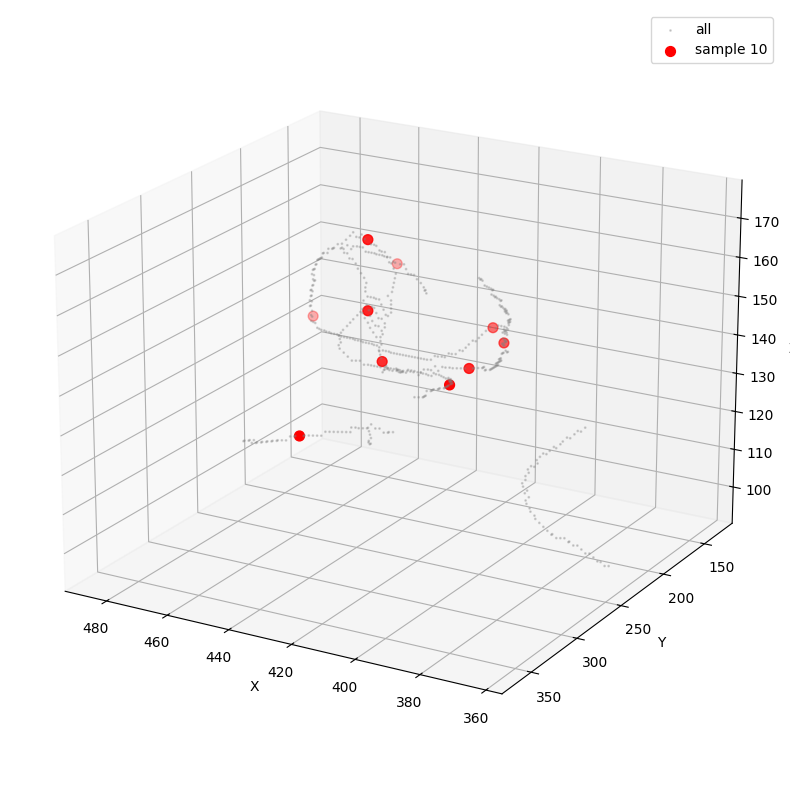

In [ ]:
point_cloud = np.vstack([np.where(skeleton_labeled_image>0)]).T
sample_points = sample_on_original_points_pca(point_cloud, num_samples=10)
visualize_sample_points(point_cloud,sample_points)

### 根据点采集mask里面的ROI

In [ ]:
para_path = 'D:\desktop\stent\interior\save\mr\\voxel_and_dim_info.json' #存储了体素大小基本信息的参数文件
with open(para_path, 'r', encoding='utf-8') as f:
    loaded_data = json.load(f)
    x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = loaded_data['x_voxel_size'], loaded_data['y_voxel_size'], loaded_data['z_voxel_size'], loaded_data['x_dim_max'], loaded_data['y_dim_max'], loaded_data['z_dim_max']

## 设置几何
geo = set_geo(nVoxel=np.array([z_dim_max, x_dim_max, y_dim_max]),
              dVoxel=np.array([z_voxel_size, x_voxel_size, y_voxel_size]),
              nDetector=np.array([1024,1024]),
              dDetector=np.array([0.5,0.5]))
angles = np.linspace(0,2*np.pi,360)

## 读取文件
mask_path = 'D:\desktop\stent\interior\save\mr\\tif\label\\topcow_mr_001_0000.tif'
mask = tiff.imread(mask_path)

## 首先将roi区域内的mask内容提取出来，作为图像的真值
save_path = 'D:\desktop\stent\interior\\train_data'
gt_save_path = join(save_path,'gt_vol')
proj_save_path = join(save_path,'gt_proj')
os.makedirs(gt_save_path, exist_ok=True)
os.makedirs(proj_save_path, exist_ok=True)

radius = 50
for index,point in enumerate(sample_points):
    roi_center = np.array([point[0], point[1], point[2]])

    ## 这里的image应该是mask
    point_mesh = get_circle_roi(mask.shape,roi_center,50) # (3, N)的点云形式 #真值

    ## 进行投影
    roi_proj,src_proj = get_roi_proj(mask,geo,angles,point_mesh)

    ## 将ROI的点云形式转换为体素形式的mask
    mask_mask = np.zeros([z_dim_max, x_dim_max, y_dim_max], dtype=bool)
    for i in point_mesh.T:
        z_idx = int(round(i[0]))
        x_idx = int(round(i[1]))
        y_idx = int(round(i[2]))
        mask_mask[z_idx, x_idx, y_idx] = True
    gt = np.where(mask_mask, mask, 0)
    
    tiff.imwrite(join(gt_save_path,f"vol_gt_sample{index}.tif"),gt.astype(np.float32))
    tiff.imwrite(join(proj_save_path,f"vol_proj_sample{index}.tif"),roi_proj.astype(np.float32))

    print(index)
    break


0


In [153]:
mask.shape

(248, 510, 636)

In [127]:
mask.shape

(248, 510, 636)

In [156]:
visualize_point_cloud(point_mesh.T)

### 整合流程

In [ ]:
## 找到满足要求的动脉区域（最有可能发生脑梗塞的区域）
def find_counterpart(mask,main_artery_indices):
    mask = np.round(mask).astype(np.uint8)
    mask_i = np.isin(mask, main_artery_indices)
    mask_filtered = np.where(mask_i, mask, 0)
    return mask_filtered

## 生成ROI区域的外接圆（半径应该稍微设置大一点）
def get_filled_bounding_cube_from_sphere(
    center: np.ndarray,
    radius: float,
    resolution_steps: int = 200  # 正方体每个轴上采样的点数 (例如 32x32x32)
) -> np.ndarray:
    """
    根据球体中心和半径，直接生成其外接正方体内部所有点的点云表示。

    Args:
        center: 球体的中心坐标 (Cx, Cy, Cz)。
        radius: 球体的半径 R。
        resolution_steps: 正方体每个轴上均匀采样的点数 (体素分辨率 M)。

    Returns:
        filled_cube_points: 填充了整个正方体体积的点云，形状为 (M^3, 3)。
    """
    
    C_z, C_x, C_y = center
    R = radius

    # --- 1. 确定外接正方体的边界 ---
    
    # 最小和最大边界（这里就可以看出，得到的正方形的边长是2*R+1，在体素空间中）
    X_min, X_max = C_x - R, C_x + R
    Y_min, Y_max = C_y - R, C_y + R
    Z_min, Z_max = C_z - R, C_z + R
    
    # 检查基本条件
    if R <= 0:
        print("警告：半径必须大于0。返回空点云。")
        return np.empty((0, 3))
    if resolution_steps < 2:
        # 至少需要2个点来定义范围
        resolution_steps = 2
        
    # --- 2. 生成填充整个正方体体积的点云 ---
    
    # 在每个轴上生成均匀分布的坐标
    # 在 [Min, Max] 范围内生成 M 个点
    x_grid = np.linspace(X_min, X_max, resolution_steps)
    y_grid = np.linspace(Y_min, Y_max, resolution_steps)
    z_grid = np.linspace(Z_min, Z_max, resolution_steps)
    
    # 使用 np.meshgrid 生成所有组合的坐标
    # indexing='ij' 适用于图像和体素处理，确保 XYZ 轴正确对应
    Z, X, Y = np.meshgrid(z_grid, x_grid, y_grid, indexing='ij')

    # 将三维网格展平为 (M^3, 3) 的点云形式
    filled_cube_points = np.stack([Z.flatten(), X.flatten(), Y.flatten()], axis=1)
    
    return filled_cube_points


def voxelize(
    point_cloud: np.ndarray, 
    voxel_size = (256, 128, 128), 
    fill_value = 1
) -> np.ndarray:
    """
    使用 NumPy 矢量化操作快速将点云体素化为占用网格。

    Args:
        point_cloud: 形状为 (N, 3) 的点云数组，坐标顺序为 (Z, X, Y)。
        voxel_size: 体素网格的维度 (Depth, Height, Width) 或 (Z, X, Y)。
        fill_value: 用于标记占用体素的值 (通常是 1)。

    Returns:
        voxel: 形状为 voxel_size 的体素占用网格 (NumPy 数组)。
    """
    
    # 1. 坐标取整并转换为整数索引
    indices = np.round(point_cloud).astype(int) 
    
    Z_indices = indices[:, 0]
    X_indices = indices[:, 1]
    Y_indices = indices[:, 2]

    D, H, W = voxel_size # D=Z_max, H=X_max, W=Y_max
    
    # 确保索引在 [0, size-1] 范围内
    valid_mask = (Z_indices >= 0) & (Z_indices < D) & \
                 (X_indices >= 0) & (X_indices < H) & \
                 (Y_indices >= 0) & (Y_indices < W)

    # 3. 筛选有效索引
    valid_Z = Z_indices[valid_mask]
    valid_X = X_indices[valid_mask]
    valid_Y = Y_indices[valid_mask]
    
    # 将三个坐标数组堆叠起来，形成 (M, 3) 形状的有效索引数组
    valid_indices = (valid_Z, valid_X, valid_Y)
    
    # 4. 创建并填充体素网格
    # 初始化体素网格
    voxel = np.zeros(voxel_size, dtype=np.float32) 
    
    # 利用 NumPy 的高级索引（矢量化）一次性设置所有有效体素的值
    # 这是关键步骤，取代了 Python 循环
    voxel[valid_indices] = fill_value
    
    return voxel

def sample_on_original_points_pca(points: np.ndarray, num_samples: int = 10):
    """
    通过 PCA 找到最长轴，将点云排序后，沿着该轴均匀选择原始点云上的点。
    
    参数:
        points: np.ndarray (N, 3) 原始点云坐标
        num_samples: int，采样数量
    返回:
        samples: np.ndarray (num_samples, 3) 选自原始点云的坐标
    """
    if len(points) < num_samples:
        return points # 点太少，返回全部

    # 1. PCA 分解 (与原代码相同)
    centered = points - points.mean(axis=0)
    cov = np.cov(centered.T)
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]
    main_dir = eigvecs[:, 0]

    # 2. 投影到主轴，并根据投影值排序
    projections = centered @ main_dir
    # 获取排序后的索引：沿着主轴从小到大排列
    sorted_indices = np.argsort(projections)

    # 3. 均匀采样索引
    total_points = len(points)
    
    # 确定采样间隔
    interval = total_points / num_samples
    
    # 确定一个随机起始偏移量 (确保随机性)
    start_offset = np.random.uniform(0, interval)

    # 生成 num_samples 个均匀采样的浮点索引
    floating_indices = np.arange(num_samples) * interval + start_offset
    
    # 将浮点索引转换为整数索引 (并取模确保不越界)
    sample_indices = np.floor(floating_indices).astype(np.int32) % total_points

    # 4. 从排序后的索引中取出采样的点
    # 选中排序后列表中的这些点
    selected_indices_in_original = sorted_indices[sample_indices]
    
    # 返回原始坐标
    samples_on_original = points[selected_indices_in_original]
    
    return samples_on_original

def extract_centerlines(main_artery_mask, min_length=10):
    """
    对三维二值掩码进行骨架化，并分离出多条独立的中心线。

    参数:
        main_artery_mask (np.ndarray): 主血管的三维布尔/二值掩码 (D, H, W)。
        min_length (int): 过滤掉长度小于此值的短小中心线段。

    返回:
        centerlines_list (list): 包含每条独立中心线坐标点的列表。
        skeleton_labeled (np.ndarray): 带有标签的中心线三维图像 (D, H, W)。
    """
    
    if main_artery_mask.ndim != 3:
        raise ValueError("输入掩码必须是三维数组。")
    skeleton = skeletonize_3d(main_artery_mask)
    skeleton_labeled, num_labels = label(skeleton, return_num=True)
    centerlines_list = []
    for region in regionprops(skeleton_labeled):
        if region.area >= min_length:
            coords = region.coords
            centerlines_list.append(coords)
    return centerlines_list, skeleton_labeled

def get_roi(mask, sample_point, para_path, radius=50, angles = np.linspace(0,2*np.pi,360)):
    """
    mask: 图像的mask
    sample_point: 一个中心点
    para_path: 图像的参数的文件
    radius: 采样圆的半径
    """
    ## 处理单个对象，得到其截断图像（非截断区域设置为0）

    ## 设置几何
    x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)
    geo = set_geo(nVoxel=np.array([z_dim_max, x_dim_max, y_dim_max]),
                dVoxel=np.array([z_voxel_size, x_voxel_size, y_voxel_size]),
                nDetector=np.array([1024,1024]),
                dDetector=np.array([0.5,0.5]))

    # for index,point in enumerate(sample_points):
    roi_center = np.array([sample_point[0], sample_point[1], sample_point[2]])
    ## 这里的image应该是mask
    point_mesh = get_circle_roi(mask.shape,roi_center,radius) # (3, N)的点云形式 #真值

    ## 进行投影
    roi_proj,_ = get_roi_proj(mask,geo,angles,point_mesh)

    ## 将ROI的点云形式转换为体素形式的mask
    mask_mask = np.zeros([z_dim_max, x_dim_max, y_dim_max], dtype=bool)
    for i in point_mesh.T:
        z_idx = int(round(i[0]))
        x_idx = int(round(i[1]))
        y_idx = int(round(i[2]))
        mask_mask[z_idx, x_idx, y_idx] = True
    roi_gt = np.where(mask_mask, mask, 0)

    return roi_proj,roi_gt

def read_para(para_path):
    # 读取几何参数
    with open(para_path, 'r', encoding='utf-8') as f:
        loaded_data = json.load(f)
        x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = loaded_data['x_voxel_size'], loaded_data['y_voxel_size'], loaded_data['z_voxel_size'], loaded_data['x_dim_max'], loaded_data['y_dim_max'], loaded_data['z_dim_max']
    return float(x_voxel_size), float(y_voxel_size), float(z_voxel_size), int(x_dim_max), int(y_dim_max), int(z_dim_max)

def truncate_image_single(image, sample_point, para_path, radius=50, more_radius = 5): #截取单个图像
    ## 只截取ROi的区域（因为实际的数据采集中，探测器大小和重建区域大小也只有ROI的大小）
    """
    输入数据为重建得到的图像以及真实的图像，以及采样点。是对单个数据的处理
    """

    _, _, _, x_dim_max, y_dim_max, z_dim_max = read_para(para_path) #存储了体素大小基本信息的参数文件

    ## 得到正方形的roi区域
    roi_trun = np.zeros([2*(radius + more_radius), 2*(radius + more_radius), 2*(radius + more_radius)]) #包含圆形ROI的外接正方形

    point_cloud_cube = get_filled_bounding_cube_from_sphere(np.array(sample_point), radius + more_radius, resolution_steps=4*(radius+more_radius) )
    roi_image_mask = voxelize(point_cloud_cube,voxel_size = (z_dim_max,x_dim_max,y_dim_max))

    truncate_vol = np.where(roi_image_mask, image, np.min(image))

    ## 将有效区域拿出来
    border = np.array(np.where(roi_image_mask>0)).T
    border_min = np.min(border,axis=0)
    border_max = np.max(border,axis=0)
    start_indices = border_min
    end_indices = border_max + 1
    slices = tuple(slice(start, end) for start, end in zip(start_indices, end_indices))

    ## 将其值赋值到截断图像上
    roi_trun = truncate_vol[slices]

    return roi_trun

def truncate_image(vol_train, vol_gt, sample_point, para_path, radius=50, more_radius = 5):
    ## 只截取ROi的区域（因为实际的数据采集中，探测器大小和重建区域大小也只有ROI的大小）
    """
    输入数据为重建得到的图像以及真实的图像，以及采样点。是对单个数据的处理
    """

    _, _, _, x_dim_max, y_dim_max, z_dim_max = read_para(para_path) #存储了体素大小基本信息的参数文件

    # # 截断图像存储的位置
    # trun_vol_gt_save_path = join(save_dir,'truncate_vol_gt')
    # trun_vol_train_save_path = join(save_dir,'truncate_vol_train')
    # os.makedirs(trun_vol_gt_save_path,exist_ok=True)
    # os.makedirs(trun_vol_train_save_path,exist_ok=True)

    ## 得到正方形的roi区域
    roi_trun_train = np.zeros([2*(radius + more_radius), 2*(radius + more_radius), 2*(radius + more_radius)]) #包含圆形ROI的外接正方形
    roi_trun_gt = copy.deepcopy(roi_trun_train)

    point_cloud_cube = get_filled_bounding_cube_from_sphere(np.array(sample_point), radius + more_radius, resolution_steps=4*(radius+more_radius) )
    roi_image_mask = voxelize(point_cloud_cube,voxel_size = (z_dim_max,x_dim_max,y_dim_max))

    truncate_vol_gt = np.where(roi_image_mask, vol_gt, np.min(vol_gt))
    truncate_vol_train = np.where(roi_image_mask, vol_train, np.min(vol_train))

    ## 将有效区域拿出来
    border = np.array(np.where(roi_image_mask>0)).T
    border_min = np.min(border,axis=0)
    border_max = np.max(border,axis=0)
    start_indices = border_min
    end_indices = border_max + 1
    slices = tuple(slice(start, end) for start, end in zip(start_indices, end_indices))

    ## 将其值赋值到截断图像上
    roi_trun_gt = truncate_vol_gt[slices]
    # tiff.imwrite(join(trun_vol_gt_save_path,i),roi_trun_gt)

    roi_trun_train = truncate_vol_train[slices]
    # tiff.imwrite(join(trun_vol_train_save_path,i),roi_trun_train)

    return roi_trun_train,roi_trun_gt

# def truncate_image(vol_train_dir, vol_gt_dir, sample_point_cloud, para_path, save_dir, radius=50, more_radius = 5):
#     ## 只截取ROi的区域（因为实际的数据采集中，探测器大小和重建区域大小也只有ROI的大小）
#     """
#     输入数据为重建得到的图像以及真实的图像，以及采样点。是对单个数据的处理
#     """

#     _, _, _, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)

#     radius = 50
#     vol_train_list = sorted(os.listdir(vol_train_dir))
#     vol_gt_list = sorted(os.listdir(vol_gt_dir))

#     trun_vol_gt_save_path = join(save_dir,'truncate_vol_gt')
#     trun_vol_train_save_path = join(save_dir,'truncate_vol_train')
#     os.makedirs(trun_vol_gt_save_path,exist_ok=True)
#     os.makedirs(trun_vol_train_save_path,exist_ok=True)

#     # 得到裁剪的ROI区域
#     more_radius = 5
#     for index,i in enumerate(vol_train_list):
#         roi_trun = np.zeros([2*(radius + more_radius), 2*(radius + more_radius), 2*(radius + more_radius)]) #包含圆形ROI的外接正方形
#         vol_train = tiff.imread(join(vol_train_dir,vol_train_list[index]))
#         vol_gt = tiff.imread(join(vol_gt_dir,vol_gt_list[index]))
#         sample_point = sample_point_cloud[index]
        
#         ## 得到正方形的roi区域
#         point_cloud_cube = get_filled_bounding_cube_from_sphere(np.array(sample_point), radius + more_radius, resolution_steps=4*(radius+more_radius) )
#         roi_image_mask = voxelize(point_cloud_cube,voxel_size = (z_dim_max,x_dim_max,y_dim_max))

#         truncate_vol_gt = np.where(roi_image_mask, vol_gt, np.min(vol_gt))
#         truncate_vol_train = np.where(roi_image_mask, vol_train, np.min(vol_train))

#         ## 将有效区域拿出来
#         border = np.array(np.where(roi_image_mask>0)).T
#         border_min = np.min(border,axis=0)
#         border_max = np.max(border,axis=0)
#         start_indices = border_min
#         end_indices = border_max + 1
#         slices = tuple(slice(start, end) for start, end in zip(start_indices, end_indices))

#         ## 将其值赋值到截断图像上
#         roi_trun.fill(0)
#         roi_trun = truncate_vol_gt[slices]
#         tiff.imwrite(join(trun_vol_gt_save_path,i),roi_trun)

#         roi_trun.fill(0)
#         roi_trun = truncate_vol_train[slices]
#         tiff.imwrite(join(trun_vol_train_save_path,i),roi_trun)
#         print(i)


def recon_single_object(proj, angles, para_path):
    """
    proj: 需要重建的图像
    angles: 角度
    para_path: 图像几何的参数文件
    """
    x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)
    geo = set_geo(nVoxel=np.array([z_dim_max, x_dim_max, y_dim_max]),
                dVoxel=np.array([z_voxel_size, x_voxel_size, y_voxel_size]),
                nDetector=np.array([1024,1024]),
                dDetector=np.array([0.5,0.5]))
    
    recon_img = algs.fdk(proj,geo,angles)
    return recon_img


# 下面这个work的思路是直接得到真实图像和训练图像，但是应该是先得到完整的投影和图像，再选择角度去反投影。最后一步才是裁剪，
def get_sample_proj_vol(mask_dir,para_path, save_dir = './', number_roi_in_one_sample = 10, save_file = False, radius=50, more_radius = 5):
    # 设置保存路径
    centerline_save_path = join(save_dir,'centerline')
    point_cloud_save_path = join(save_dir,'point_cloud')
    os.makedirs(centerline_save_path, exist_ok=True)
    os.makedirs(point_cloud_save_path, exist_ok=True)
    # if(save_file):
    # 如果需要保留这些中间文件
    vol_gt_save_path = join(save_dir,'vol_gt')
    proj_gt_save_path = join(save_dir,'proj_gt')
    # vol_train_save_path = join(save_path,'vol_train')
    # proj_train_save_path = join(save_path,'proj_train')
    os.makedirs(vol_gt_save_path, exist_ok=True)
    os.makedirs(proj_gt_save_path, exist_ok=True)
    # os.makedirs(vol_train_save_path, exist_ok=True)
    # os.makedirs(proj_train_save_path, exist_ok=True)

    x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)

    # 规划主要动脉标签
    main_artery = ['L-M1','R-M1','L-A1A2','R-A1A2','L-A1A2','BA'] # 大脑中动脉、前动脉、后动脉、基地动脉都是比较任意发生脑梗塞的区域
    main_artery_indices = []
    LABEL_TO_IDX = {data['LABEL']: idx for idx, data in BRAIN_VESSEL_LABELS_MR.items()}
    for label in main_artery:
        idx = LABEL_TO_IDX.get(label)
        if idx is not None:
            main_artery_indices.append(idx)
        else:
            print(f"警告：标签 '{label}' 未在字典中找到。")

    # 其他参数
    angles = np.linspace(0,2*np.pi,360)
    radius = radius

    ## 对每个mask，都在主动脉区域选取10个点，并截取以这个点为圆心的圆形区域作为训练数据
    # num = 0
    for i in os.listdir(mask_dir):
        # 取得主要动脉的中心线
        mask = tiff.imread(join(mask_dir,i))
        main_artery_mask = find_counterpart(mask,main_artery_indices)
        _, skeleton_labeled = extract_centerlines(main_artery_mask)
        tiff.imwrite(join(centerline_save_path,i),skeleton_labeled.astype(np.uint8))

        # 在这些中心线上均匀且随机的取10个点
        point_cloud = np.vstack([np.where(skeleton_labeled>0)]).T #skeleton_labeled 来自于mask, 因此point_cloud的点坐标是(z,x,y), 因此sample_points的点坐标也是(z,x,y)
        sample_points = sample_on_original_points_pca(point_cloud, num_samples=number_roi_in_one_sample)
        
        # 保存选取的点
        convert_point_cloud_to_ply(sample_points,join(point_cloud_save_path,i.split('.')[0]+'.ply'))

        # 以点为中心取ROI区域
        mask[mask>0] = 1 #将mask置为0-12
        
        # 首先将roi区域内的mask内容提取出来，作为图像的真值
        for sample_idnex, sample_point in enumerate(sample_points):
            # 获得该中心点对应的roi
            roi_proj,roi_gt = get_roi(mask=mask, sample_point=sample_point, para_path=para_path, angles=angles, radius=radius) #与原始投影、原始图像的大小是一样的，但是只有ROI的区域有值，其他地方都是0
            
            save_name = f"{i.split('.')[0]}_sample_{str(sample_idnex).zfill(2)}.tif"

            tiff.imwrite(join(vol_gt_save_path,save_name),roi_gt)
            tiff.imwrite(join(proj_gt_save_path,save_name),roi_proj)

            # # 重建投影
            # angles = np.linspace(0,2*np.pi,360)
            # recon_img = recon_single_object(roi_proj, angles, para_path=para_path)
            
            # # 将有效区域截取出来
            # truncate_image(vol_train, vol_gt, sample_point, para_path, save_dir, radius=50, more_radius = 5):
        print(i)
        # break
        # num += 1
        # if(num==2):
        #     break

def get_truncated_image(vol_train_dir, vol_gt_dir,  save_dir, sample_pc_dir, para_path, radius=50, more_radius = 5):
    # 从稀疏采集之后的投影的重建结果中截取有效区域。稀疏前后的名字应该还是一样的
    vol_train_list = sorted(os.listdir(vol_train_dir))
    vol_gt_list = sorted(os.listdir(vol_gt_dir))

    trun_vol_gt_save_path = join(save_dir,'vol_gt')
    trun_vol_train_save_path = join(save_dir,'vol_train')
    os.makedirs(trun_vol_gt_save_path,exist_ok=True)
    os.makedirs(trun_vol_train_save_path,exist_ok=True)

    for index,i in enumerate(vol_train_list):
        sample_name = i.split('_sample_')[0]
        point_index = int(i.split('_')[-1].split('.')[0])
        sample_points = read_ply(join(sample_pc_dir,sample_name+'.ply')) #
        vol_train = tiff.imread(join(vol_train_dir,vol_train_list[index]))
        vol_gt = tiff.imread(join(vol_gt_dir,vol_gt_list[index]))
        point = sample_points[point_index]
        trun_vol_train, trun_vol_gt = truncate_image(vol_train,vol_gt,point,para_path, radius, more_radius)
        tiff.imwrite(join(trun_vol_gt_save_path,i),trun_vol_gt)
        tiff.imwrite(join(trun_vol_train_save_path,i),trun_vol_train)

        print(i)

#### 生成ROI数据

In [ ]:
## 得到多个小ROI的数据

mask_dir = '/data1/liuyang/stent/interior/data/root_data/tif/label'
save_dir = '/data1/liuyang/stent/interior/data/src_data'
para_path = '/data1/liuyang/stent/interior/data/voxel_and_dim_info.json' #存储了体素大小基本信息的参数文件
get_sample_proj_vol(mask_dir=mask_dir, save_dir=save_dir, para_path=para_path, number_roi_in_one_sample=10)

/tmp/ipykernel_2826662/2091121999.py:176: FutureWarning: `skeletonize_3d` is deprecated since version 0.23 and will be removed in version 0.25. Use `skimage.morphology.skeletonize` instead.
  skeleton = skeletonize_3d(main_artery_mask)


mr_011.tif
mr_018.tif
mr_006.tif
mr_020.tif
mr_005.tif
mr_016.tif
mr_001.tif
mr_012.tif
mr_026.tif
mr_021.tif
mr_022.tif
mr_015.tif
mr_008.tif
mr_013.tif
mr_004.tif
mr_017.tif
mr_014.tif
mr_025.tif
mr_002.tif
mr_010.tif
mr_007.tif
mr_023.tif
mr_003.tif
mr_027.tif
mr_024.tif


In [ ]:
# ## 测试一下truncated函数
# # 首先先重建原图
# proj_path = 'D:\desktop\stent\interior\save\mr\\train_data\proj_gt'
# vol_train_save_path = 'D:\desktop\stent\interior\save\mr\\train_data\\vol_train'
# for i in os.listdir(proj_path):
#     proj = tiff.imread(join(proj_path,i))
#     angles = np.linspace(0,2*np.pi,360)
#     recon_img = recon_single_object(proj,para_path=para_path,angles=angles)
#     tiff.imwrite(join(vol_train_save_path,i),recon_img)

# 接着再进行截取
vol_train_dir = '/data1/liuyang/stent/interior/data/train_data/25_4-fdkNoFilter/vol_train'
vol_gt_dir = '/data1/liuyang/stent/interior/data/train_data/25_4-fdkNoFilter/vol_gt'
sample_pc_dir = '/data1/liuyang/stent/interior/data/src_data/point_cloud'
save_dir = '/data1/liuyang/stent/interior/data/trun_train_data'
get_truncated_image(vol_train_dir, vol_gt_dir, save_dir, sample_pc_dir, para_path)

#### 稀疏重建并截取ROI区域

In [ ]:
## 稀疏采样重建之后直接截取，不然会消耗很多存储空间
def sparse_recon(proj_path, gt_path, tar_range, tar_num, save_dir, para_path, sample_pc_dir, filter = False):
    if(filter):
        save_path = join(save_dir,f"{tar_range}_{tar_num}-fdkYesFilter")
    else:
        save_path = join(save_dir,f"{tar_range}_{tar_num}-fdkNoFilter")
    
    vol_train_save_path = join(save_path,'vol_train')
    vol_gt_save_path = join(save_path,'vol_gt')
    os.makedirs(vol_train_save_path, exist_ok=True)
    os.makedirs(vol_gt_save_path, exist_ok=True)
    x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)
    geo = set_geo(nVoxel=np.array([z_dim_max, x_dim_max, y_dim_max]),
                dVoxel=np.array([z_voxel_size, x_voxel_size, y_voxel_size]),
                nDetector=np.array([1024,1024]),
                dDetector=np.array([0.5,0.5]))

    # 180度范围内，尽量多取几例数据来训练
    radius = 50
    more_radius = 5

    proj_list = sorted(os.listdir(proj_path))
    gt_list = sorted(os.listdir(gt_path))
    for index,i in enumerate(proj_list):
        proj  = tiff.imread(join(proj_path,proj_list[index]))
        vol_gt = tiff.imread(join(gt_path,gt_list[index]))

        ranges = int(180 / tar_range)
        ranges_to_chose = ranges
        if(ranges >= 10):
            ranges_to_chose = 10 #最多采集10个吧，太多了也不行

        sample_name = i.split('_sample_')[0] # 类似于: mr_001_sample_00.tif
        point_index = int(i.split('_')[-1].split('.')[0])
        sample_points = read_ply(join(sample_pc_dir,sample_name+'.ply')) #
        point = sample_points[point_index]
        vol_gt_truncated = truncate_image_single(vol_gt, point, para_path, radius = radius, more_radius=more_radius)

        for j in random.sample(range(ranges), k=ranges_to_chose):
            index = np.linspace(tar_range*j, tar_range*(j+1), tar_num, endpoint=False).astype(np.uint8)
            angles = np.linspace(np.deg2rad(tar_range*j), np.deg2rad(tar_range*(j+1)), tar_num, endpoint=False) #120个角度
            proj_part = proj[index]
            
            if(filter):
                imgFDK = algs.fdk(proj_part, geo, angles) #有限角的重建结果
            else:
                imgFDK = algs.fdk_no_filter(proj_part, geo, angles) #fdk不用滤波重建
            
            vol_train_truncated = truncate_image_single(imgFDK, point, para_path, radius = radius, more_radius=more_radius)
            
            file_name = f'{i.split(".")[0]}_{str(int(tar_range*j))}-{str(int(tar_range*(j+1)))}.tif'

            tiff.imwrite(join(vol_train_save_path, file_name), vol_train_truncated)
            tiff.imwrite(join(vol_gt_save_path, file_name), vol_gt_truncated)

            # tiff.imwrite(join(vol_train_save_path, file_name), imgFDK)
            # shutil.copy(join(gt_path,i),join(vol_gt_save_path, file_name))

            # imgFDK、join(gt_path,i)


        print(i,point_index)
        # break

proj_path = '/data1/liuyang/stent/interior/data/src_data/proj_gt'
gt_path = '/data1/liuyang/stent/interior/data/src_data/vol_gt'
save_dir = '/data1/liuyang/stent/interior/data/trun_train_data'
tar_range = 25
tar_num = 4
sample_pc_dir = '/data1/liuyang/stent/interior/data/src_data/point_cloud'
para_path = '/data1/liuyang/stent/interior/data/voxel_and_dim_info.json'
sparse_recon(proj_path, gt_path, tar_range, tar_num, save_dir, para_path=para_path, sample_pc_dir=sample_pc_dir, filter=False)

mr_001_sample_00.tif 0
mr_001_sample_01.tif 1
mr_001_sample_02.tif 2
mr_001_sample_03.tif 3
mr_001_sample_04.tif 4
mr_001_sample_05.tif 5
mr_001_sample_06.tif 6
mr_001_sample_07.tif 7
mr_001_sample_08.tif 8
mr_001_sample_09.tif 9
mr_002_sample_00.tif 0
mr_002_sample_01.tif 1
mr_002_sample_02.tif 2
mr_002_sample_03.tif 3
mr_002_sample_04.tif 4
mr_002_sample_05.tif 5
mr_002_sample_06.tif 6
mr_002_sample_07.tif 7
mr_002_sample_08.tif 8
mr_002_sample_09.tif 9
mr_003_sample_00.tif 0
mr_003_sample_01.tif 1
mr_003_sample_02.tif 2
mr_003_sample_03.tif 3
mr_003_sample_04.tif 4
mr_003_sample_05.tif 5
mr_003_sample_06.tif 6
mr_003_sample_07.tif 7
mr_003_sample_08.tif 8
mr_003_sample_09.tif 9
mr_004_sample_00.tif 0
mr_004_sample_01.tif 1
mr_004_sample_02.tif 2
mr_004_sample_03.tif 3
mr_004_sample_04.tif 4
mr_004_sample_05.tif 5
mr_004_sample_06.tif 6
mr_004_sample_07.tif 7
mr_004_sample_08.tif 8
mr_004_sample_09.tif 9
mr_005_sample_00.tif 0
mr_005_sample_01.tif 1
mr_005_sample_02.tif 2
mr_005_samp

#### 检查数据

In [116]:
### 检察一下生成的文件，将tif文件转换为jpg文件去检查

# src_path = '/data1/liuyang/stent/interior/data/trun_train_data'
# save_path = '/data1/liuyang/stent/interior/data/trun_train_data/train_save_to_check'
src_path = '/data1/liuyang/stent/interior/data/trun_test_data'
save_path = '/data1/liuyang/stent/interior/data/trun_train_data/test_save_to_check'

to_down  = ['25_4-fdkNoFilter','45_4-fdkNoFilter','90_4-fdkNoFilter']

index = np.linspace(0,111,20,endpoint=False)
for i in to_down:
    vol_path = join(src_path,i)
    # os.makedirs(save_dir,exist_ok=True)
    for j in os.listdir(vol_path):
        vol_train_gt_path = join(vol_path,j)
        # print(join(vol_path,j))
        save_dir = join(save_path,i,j)
        for m in os.listdir(vol_train_gt_path):
            proj = tiff.imread(join(vol_train_gt_path,m))
            proj_save_path = join(save_dir,m.split('.')[0])
            os.makedirs(proj_save_path,exist_ok=True)
            for k in index:
                k = int(k)
                trans_tif_rgb(proj[k]).save(join(proj_save_path,str(k).zfill(2)+'.jpg'))

/tmp/ipykernel_2826662/426079101.py:70: RuntimeWarning: invalid value encountered in divide
  tif_data = (tif_data-np.min(tif_data))/(np.max(tif_data)-np.min(tif_data))
/tmp/ipykernel_2826662/426079101.py:72: RuntimeWarning: invalid value encountered in cast
  tif_data = tif_data.astype(np.uint8)


In [ ]:
# ## 检查以下pl7y文件

# pc = read_ply('D:\desktop\stent\interior\save\mr\\train_data\point_cloud\\topcow_mr_001_0000.ply')
# center_line = tiff.imread('D:\desktop\stent\interior\save\mr\\train_data\centerline\\topcow_mr_001_0000.tif')

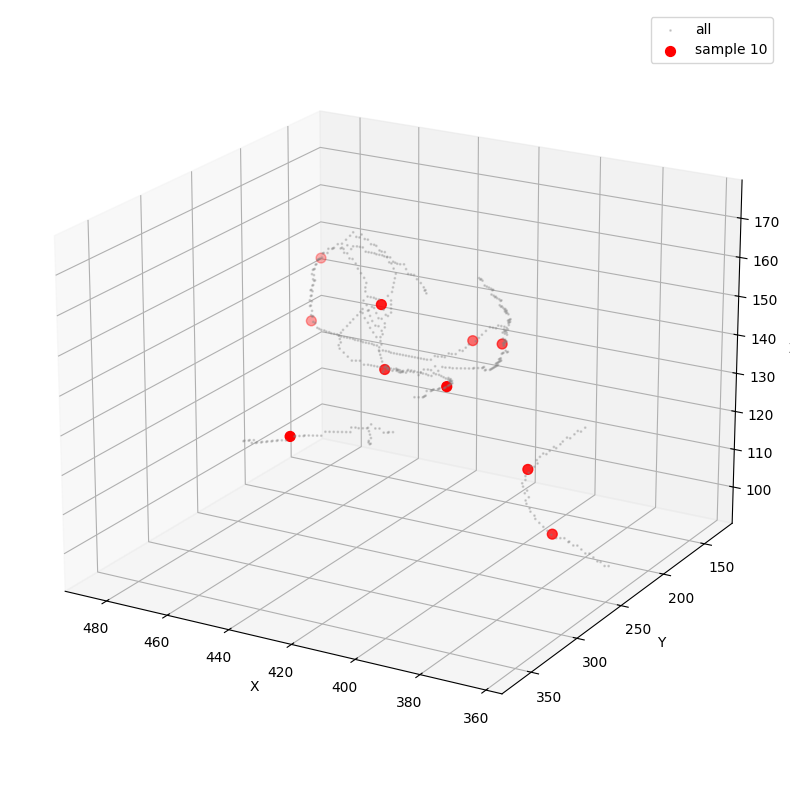

In [ ]:
# center_line_pc = np.vstack([np.where(center_line>0)]).T
# visualize_sample_points(center_line_pc,pc)

In [ ]:
# center_line.shape

(248, 510, 636)

In [ ]:
# visualize_point_cloud(center_line_pc)

### 重建ROI投影

In [31]:
def recon(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max, proj_path, save_path, angles):
    geo = set_geo(nVoxel=np.array([z_dim_max, x_dim_max, y_dim_max]),
                dVoxel=np.array([z_voxel_size, x_voxel_size, y_voxel_size]),
                nDetector=np.array([1024,1024]),
                dDetector=np.array([0.5,0.5]))
    for i in os.listdir(proj_path):
        proj = tiff.imread(join(proj_path,i))
        recon_img = algs.fdk(proj,geo,angles)
        tiff.imwrite(join(save_path,i),recon_img)
        print(i)

def proj(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max, vol_path, save_path, angles):
    geo = set_geo(nVoxel=np.array([z_dim_max, x_dim_max, y_dim_max]),
                dVoxel=np.array([z_voxel_size, x_voxel_size, y_voxel_size]),
                nDetector=np.array([1024,1024]),
                dDetector=np.array([0.5,0.5]))
    for i in os.listdir(vol_path):
        vol = tiff.imread(join(vol_path,i))
        proj_image = tigre.Ax(vol,geo,angles)
        tiff.imwrite(join(save_path,i),proj_image)
        print(i)

In [32]:
proj_path = 'D:\desktop\stent\interior\save\mr\\train_data\\gt_proj'
save_dir = 'D:\desktop\stent\interior\save\mr\\train_data\\train_vol'
para_path = 'D:\desktop\stent\interior\save\mr\\voxel_and_dim_info.json' #存储了体素大小基本信息的参数文件
os.makedirs(save_dir,exist_ok=True)

# 读取几何参数
x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)
angles = np.linspace(0,2*np.pi,360)

recon(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max, proj_path=proj_path, save_path=save_dir, angles=angles)

vol_proj_sample0.tif
vol_proj_sample1.tif
vol_proj_sample2.tif
vol_proj_sample3.tif
vol_proj_sample4.tif
vol_proj_sample5.tif
vol_proj_sample6.tif
vol_proj_sample7.tif
vol_proj_sample8.tif
vol_proj_sample9.tif


In [33]:
## 对重建出来的图像再次投影看看效果

vol_path = 'D:\desktop\stent\interior\save\mr\\train_data\\train_vol'
save_dir = 'D:\desktop\stent\interior\save\mr\\train_data\\train_vol_proj'
para_path = 'D:\desktop\stent\interior\save\mr\\voxel_and_dim_info.json' #存储了体素大小基本信息的参数文件
os.makedirs(save_dir,exist_ok=True)

# 读取几何参数
x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)
angles = np.linspace(0,2*np.pi,360)


proj(x_voxel_size, y_voxel_size, z_voxel_size, x_dim_max, y_dim_max, z_dim_max, vol_path=vol_path, save_path=save_dir, angles=angles)

vol_proj_sample0.tif
vol_proj_sample1.tif
vol_proj_sample2.tif
vol_proj_sample3.tif
vol_proj_sample4.tif
vol_proj_sample5.tif
vol_proj_sample6.tif
vol_proj_sample7.tif
vol_proj_sample8.tif
vol_proj_sample9.tif


### 截取ROI区域

In [ ]:
## 生成ROI区域的外接圆（半径应该稍微设置大一点）

def get_filled_bounding_cube_from_sphere(
    center: np.ndarray,
    radius: float,
    resolution_steps: int = 200  # 正方体每个轴上采样的点数 (例如 32x32x32)
) -> np.ndarray:
    """
    根据球体中心和半径，直接生成其外接正方体内部所有点的点云表示。

    Args:
        center: 球体的中心坐标 (Cx, Cy, Cz)。
        radius: 球体的半径 R。
        resolution_steps: 正方体每个轴上均匀采样的点数 (体素分辨率 M)。

    Returns:
        filled_cube_points: 填充了整个正方体体积的点云，形状为 (M^3, 3)。
    """
    
    C_z, C_x, C_y = center
    R = radius

    # --- 1. 确定外接正方体的边界 ---
    
    # 最小和最大边界
    X_min, X_max = C_x - R, C_x + R
    Y_min, Y_max = C_y - R, C_y + R
    Z_min, Z_max = C_z - R, C_z + R
    
    # 检查基本条件
    if R <= 0:
        print("警告：半径必须大于0。返回空点云。")
        return np.empty((0, 3))
    if resolution_steps < 2:
        # 至少需要2个点来定义范围
        resolution_steps = 2
        
    # --- 2. 生成填充整个正方体体积的点云 ---
    
    # 在每个轴上生成均匀分布的坐标
    # 在 [Min, Max] 范围内生成 M 个点
    x_grid = np.linspace(X_min, X_max, resolution_steps)
    y_grid = np.linspace(Y_min, Y_max, resolution_steps)
    z_grid = np.linspace(Z_min, Z_max, resolution_steps)
    
    # 使用 np.meshgrid 生成所有组合的坐标
    # indexing='ij' 适用于图像和体素处理，确保 XYZ 轴正确对应
    Z, X, Y = np.meshgrid(z_grid, x_grid, y_grid, indexing='ij')

    # 将三维网格展平为 (M^3, 3) 的点云形式
    filled_cube_points = np.stack([Z.flatten(), X.flatten(), Y.flatten()], axis=1)
    
    return filled_cube_points


def voxelize(
    point_cloud: np.ndarray, 
    voxel_size = (256, 128, 128), 
    fill_value = 1
) -> np.ndarray:
    """
    使用 NumPy 矢量化操作快速将点云体素化为占用网格。

    Args:
        point_cloud: 形状为 (N, 3) 的点云数组，坐标顺序为 (Z, X, Y)。
        voxel_size: 体素网格的维度 (Depth, Height, Width) 或 (Z, X, Y)。
        fill_value: 用于标记占用体素的值 (通常是 1)。

    Returns:
        voxel: 形状为 voxel_size 的体素占用网格 (NumPy 数组)。
    """
    
    # 1. 坐标取整并转换为整数索引
    indices = np.round(point_cloud).astype(int) 
    
    Z_indices = indices[:, 0]
    X_indices = indices[:, 1]
    Y_indices = indices[:, 2]

    D, H, W = voxel_size # D=Z_max, H=X_max, W=Y_max
    
    # 确保索引在 [0, size-1] 范围内
    valid_mask = (Z_indices >= 0) & (Z_indices < D) & \
                 (X_indices >= 0) & (X_indices < H) & \
                 (Y_indices >= 0) & (Y_indices < W)

    # 3. 筛选有效索引
    valid_Z = Z_indices[valid_mask]
    valid_X = X_indices[valid_mask]
    valid_Y = Y_indices[valid_mask]
    
    # 将三个坐标数组堆叠起来，形成 (M, 3) 形状的有效索引数组
    valid_indices = (valid_Z, valid_X, valid_Y)
    
    # 4. 创建并填充体素网格
    # 初始化体素网格
    voxel = np.zeros(voxel_size, dtype=np.float32) 
    
    # 利用 NumPy 的高级索引（矢量化）一次性设置所有有效体素的值
    # 这是关键步骤，取代了 Python 循环
    voxel[valid_indices] = fill_value
    
    return voxel

In [ ]:
point_cloud_cuba = get_filled_bounding_cube_from_sphere(np.array([200,100,100]),50)
voxel_sphere = voxelize(point_cloud_cuba)

(8000000, 3)


In [59]:
visualize_point_cloud(np.vstack(np.where(voxel_sphere>0)).T)

In [ ]:
## 下列代码是将获取到的ROI完整图像存储下来，然后再逐一读取并截取的代码


## 只截取ROi的区域（因为实际的数据采集中，探测器大小和重建区域大小也只有ROI的大小）
sample_pc_path = 'D:\desktop\stent\interior\save\mr\\train_data\point_cloud\\topcow_mr_001_0000.ply'
sample_pc = read_ply(sample_pc_path)

para_path = 'D:\desktop\stent\interior\save\mr\\voxel_and_dim_info.json' #存储了体素大小基本信息的参数文件
_, _, _, x_dim_max, y_dim_max, z_dim_max = read_para(para_path)

radius = 50
train_vol_path = 'D:\desktop\stent\interior\save\mr\\train_data\\train_vol'
gt_vol_path = 'D:\desktop\stent\interior\save\mr\\train_data\gt_vol'
vol_train_list = sorted(os.listdir(train_vol_path))
vol_gt_list = sorted(os.listdir(gt_vol_path))
# assert(vol_train_list==vol_gt_list)

save_path = 'D:\desktop\stent\interior\save\mr\\train_data\\truncate'
trun_vol_gt_save_path = join(save_path,'truncate_vol_gt')
trun_vol_train_save_path = join(save_path,'truncate_vol_train')
os.makedirs(trun_vol_gt_save_path,exist_ok=True)
os.makedirs(trun_vol_train_save_path,exist_ok=True)

# 得到裁剪的ROI区域
more_radius = 5
for index,i in enumerate(vol_train_list):
    roi_trun = np.zeros([2*(radius + more_radius), 2*(radius + more_radius), 2*(radius + more_radius)]) #包含圆形ROI的外接正方形
    vol_train = tiff.imread(join(train_vol_path,vol_train_list[index]))
    vol_gt = tiff.imread(join(gt_vol_path,vol_gt_list[index]))
    sample_point = sample_pc[index]
    
    ## 得到正方形的roi区域
    point_cloud_cube = get_filled_bounding_cube_from_sphere(np.array(sample_point), radius + more_radius, resolution_steps=4*(radius+more_radius) )
    roi_image_mask = voxelize(point_cloud_cube,voxel_size = (z_dim_max,x_dim_max,y_dim_max))

    truncate_vol_gt = np.where(roi_image_mask, vol_gt, np.min(vol_gt))
    truncate_vol_train = np.where(roi_image_mask, vol_train, np.min(vol_train))

    ## 将有效区域拿出来
    border = np.array(np.where(roi_image_mask>0)).T
    border_min = np.min(border,axis=0)
    border_max = np.max(border,axis=0)
    start_indices = border_min
    end_indices = border_max + 1
    slices = tuple(slice(start, end) for start, end in zip(start_indices, end_indices))

    ## 将其值赋值到截断图像上
    roi_trun.fill(0)
    roi_trun = truncate_vol_gt[slices]
    tiff.imwrite(join(trun_vol_gt_save_path,i),roi_trun)

    roi_trun.fill(0)
    roi_trun = truncate_vol_train[slices]
    tiff.imwrite(join(trun_vol_train_save_path,i),roi_trun)

    print(i)

## 数据增强

In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter, zoom, rotate
import random

def data_augmentation_3d(train_data: np.ndarray, gt_data: np.ndarray) -> np.ndarray:
    """
    对形状为 (z, x, y) 的数据执行一系列数据增强操作。

    参数:
        data (np.ndarray): 形状为 (z, x, y) 的输入数据。

    返回:
        np.ndarray: 增强后的数据。
    """

    augmented_data = np.copy(train_data)
    gt_aug_data = np.copy(gt_data)

    z_dim, x_dim, y_dim = augmented_data.shape
    def safe_zoom(arr, factors, output_shape):
        zoomed = zoom(arr, factors, order=1) # order=1 (线性插值)
        
        # 获取缩放后的形状
        z_new, x_new, y_new = zoomed.shape
        z_out, x_out, y_out = output_shape
        
        # 计算裁剪/填充的起始和结束点
        # 裁剪/填充在中心进行
        
        # X 轴处理
        start_x = (x_new - x_out) // 2
        end_x = start_x + x_out
        
        # Y 轴处理
        start_y = (y_new - y_out) // 2
        end_y = start_y + y_out
        
        # 对于 Z 轴，由于 factor=1, z_new 应该等于 z_out
        
        if x_new >= x_out and y_new >= y_out:
            # 裁剪 (Scale > 1)
            output = zoomed[:, start_x:end_x, start_y:end_y]
        else:
            # 填充 (Scale < 1)
            # 创建一个全零/全均值的输出数组
            # 这里选择使用原始数据的均值或最小值进行填充
            fill_value = np.min(arr)
            output = np.full(output_shape, fill_value, dtype=arr.dtype)
            
            # 找到缩放后数据在输出数组中的位置
            # (x_out - x_new) // 2 给出填充的起始位置
            pad_x_start = (x_out - x_new) // 2
            pad_y_start = (y_out - y_new) // 2

            output[:, 
                   pad_x_start : pad_x_start + x_new,
                   pad_y_start : pad_y_start + y_new] = zoomed

        return output

    random_choice = random.randint(0,1000)
    aug_way = ''

    ## 高斯模糊
    sigma_xy = random.uniform(0.1, 1.5)  # 随机选择一个适度的模糊强度
    augmented_data = gaussian_filter(augmented_data, sigma=(0, sigma_xy, sigma_xy))

    ## 随机缩放
    scale_factor = random.uniform(0.7, 1.3)  # 随机缩放因子，例如 0.8 到 1.2
    zoom_factors = (1, scale_factor, scale_factor)
    augmented_data = safe_zoom(augmented_data, zoom_factors, (z_dim, x_dim, y_dim)) #进行填充
    gt_aug_data = safe_zoom(gt_aug_data, zoom_factors, (z_dim, x_dim, y_dim)) #进行填充

    ## 随机对比度改变
    alpha = random.uniform(0.7, 1.3)  # 随机增益，例如 0.7 到 1.3
    mean_val = np.mean(augmented_data)
    augmented_data = alpha * (augmented_data - mean_val) + mean_val
    min_val, max_val = train_data.min(), train_data.max() 
    augmented_data = np.clip(augmented_data, min_val, max_val) # 防止数据越界

    ## 随机旋转
    if(random.randint(0,1)==0):
        # 旋转不是所有的都需要
        angle = random.uniform(-90, 90)  # 随机旋转角度，例如 -15 度到 15 度
        # axes=(1, 2) 表示绕 Z 轴旋转 (即在 X-Y 平面上旋转)
        augmented_data = rotate(
            augmented_data, 
            angle=angle, 
            axes=(1, 2),        # 围绕 Z 轴 (轴 0) 旋转 X (轴 1) 和 Y (轴 2)
            reshape=False,      # 保持原始形状，自动进行填充/裁剪
            order=1,            # 线性插值
            mode='constant',     # 填充模式，'constant'用cval填充(默认就是0)
            cval=0
        )
        gt_aug_data = rotate(
            gt_aug_data, 
            angle=angle, 
            axes=(1, 2),        # 围绕 Z 轴 (轴 0) 旋转 X (轴 1) 和 Y (轴 2)
            reshape=False,      # 保持原始形状，自动进行填充/裁剪
            order=1,            # 线性插值
            mode='constant',     # 填充模式，'constant'用cval填充
            cval=0
        )
        # aug_way = f'rot{str(round(angle,1))}'

    # return augmented_data,aug_way
    return augmented_data,gt_aug_data

In [ ]:
train_dir = "/data1/liuyang/stent/DTR/data/train_data/new/90_4-20-fdkNoFilter/vol_train"
gt_dir = '/data1/liuyang/stent/DTR/data/train_data/new/90_4-20-fdkNoFilter/vol_gt'

aug_train_save_dir = "/data1/liuyang/stent/DTR/data/train_data/new/90_4-20-fdkNoFilter/aug/train"
aug_gt_save_dir = '/data1/liuyang/stent/DTR/data/train_data/new/90_4-20-fdkNoFilter/aug/gt'

os.makedirs(aug_train_save_dir,exist_ok=True)
os.makedirs(aug_gt_save_dir,exist_ok=True)
file_list = os.listdir(train_dir)
random.shuffle(file_list)
augment_list = file_list[0:int(len(file_list)*0.3)]
for i in augment_list:
    gt_data = tiff.imread(join(gt_dir,i))
    train_data = tiff.imread(join(train_dir,i))
    assert train_data.shape==(256,128,128) and gt_data.shape==(256,128,128)
    augment_data,aug_gt_data = data_augmentation_3d(train_data,gt_data)
    tiff.imwrite(join(aug_train_save_dir,f"aug-{i}"),augment_data)
    tiff.imwrite(join(aug_gt_save_dir,f"aug-{i}"),aug_gt_data)

## 看一下支架会不会有截断伪影

结论：很轻微的截断伪影

In [181]:
geo = set_geo(nVoxel=np.array([256, 128, 128]),
              dVoxel=np.array([0.2, 0.2, 0.2]),
              nDetector=np.array([512,512]),
              dDetector=np.array([0.2,0.2]))
angles = np.linspace(0,2*np.pi,360)

# 在正中间截取一个圆形区域，投影再反投
stent_vol = tiff.imread('D:\desktop\stent\data\old\\vol\\stent_3.ply_01.tif').astype(np.float32)

center = np.array([stent_vol.shape[0]//2, stent_vol.shape[1]//2, stent_vol.shape[2]//2])
radius = 50

## 这里的image应该是mask
point_mesh = get_circle_roi(stent_vol.shape,center,radius) # (3, N)的点云形式 #真值

## 进行投影
roi_proj,src_proj = get_roi_proj(stent_vol,geo,angles,point_mesh)
tiff.imwrite("d:/desktop/roi_proj.tif",roi_proj.astype(np.float32))

In [179]:
np.unique(src_proj, return_counts=True)

(array([0.0000000e+00, 7.4505886e-05, 7.4505893e-05, ..., 3.1418188e+00,
        3.1954854e+00, 3.2220948e+00], dtype=float32),
 array([86166954,        1,        1, ...,        1,        1,        1],
       dtype=int64))

In [182]:
recon = algs.fdk(roi_proj, geo, angles)
tiff.imwrite("d:/desktop/recon_from_roi_proj.tif", recon.astype(np.float32))

In [180]:
point_mesh.shape

(3, 0)

In [219]:
mr_img = tiff.imread('D:\desktop\stent\interior\save\mr\\tif\label\\topcow_mr_001_0000.tif')
show_3d(mr_img)

[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.


## COSTA数据集提取出主要血管

In [6]:
len(os.listdir('/data1/liuyang/stent/interior/data/costa/trun_data/radius-64/train_data/90_4-fdkNoFilter/vol_train'))

2864

ValueError: too many values to unpack (expected 2)

## 其他

In [35]:
tiff.imread('/data1/liuyang/stent/interior/data/trun_train_data/25_4-fdkYesFilter/vol_gt/mr_001_sample_00_0-25.tif').shape

(111, 111, 111)

In [36]:
len(os.listdir('/data1/liuyang/stent/interior/data/trun_train_data/25_4-fdkYesFilter/vol_train'))

1750

In [45]:
tempProj = tiff.imread('/data1/liuyang/stent/interior/data/train_data/25_4-fdkNoFilter/vol_train/mr_001_sample_00_0-25.tif')
tempGt = tiff.imread('/data1/liuyang/stent/interior/data/train_data/25_4-fdkNoFilter/vol_gt/mr_001_sample_00_0-25.tif')

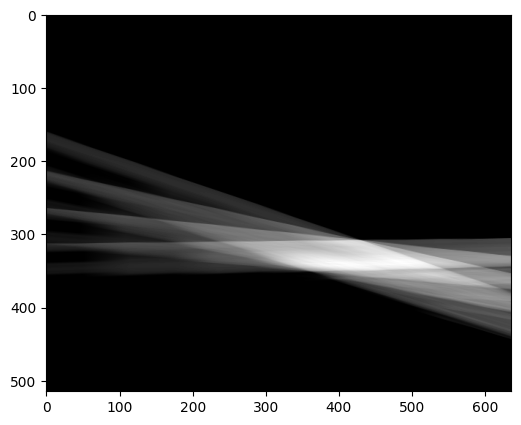

In [47]:
show_slice(tempProj[100])

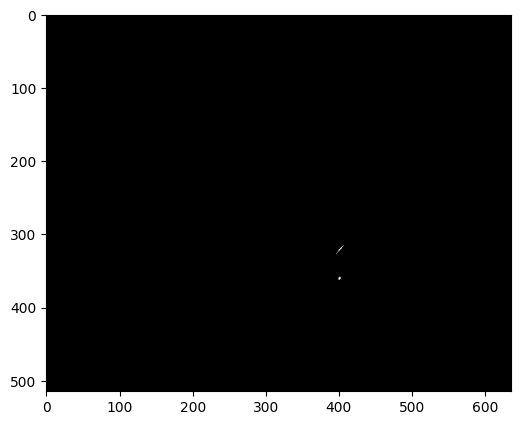

In [56]:
show_slice(tempGt[100])

### 检察一下pad函数

应该是没什么错误的

In [ ]:
def pad_to_target_size(
    input_array, 
    target_size = (128, 128, 128),
    padding_value = 0
) -> np.ndarray:
    """
    将三维 NumPy 数组填充 (Pad) 到目标尺寸，使用零填充。
    填充策略：在每个轴上尽可能居中。

    Args:
        input_array: 输入的三维数组 (D, H, W)。
        target_size: 目标形状 (D_target, H_target, W_target)。
        padding_value: 用于填充的值 (默认为 0)。

    Returns:
        padded_array: 填充后的数组，形状为 target_size。
    """
    if input_array.ndim != 3:
        raise ValueError(f"输入数组必须是三维的，但它的维度是 {input_array.ndim}。")

    # 1. 初始化填充宽度列表
    pad_width = []
    
    # 2. 计算每个维度的填充量
    for input_dim, target_dim in zip(input_array.shape, target_size):
        if input_dim > target_dim:
            raise ValueError(f"输入尺寸 {input_dim} 大于目标尺寸 {target_dim}，无法填充。")

        # 需要填充的总量
        total_padding = target_dim - input_dim
        
        # 计算前部填充量 (尽量居中)
        pad_before = total_padding // 2
        
        # 计算后部填充量 (确保总和正确)
        pad_after = total_padding - pad_before
        
        pad_width.append((pad_before, pad_after))

    # 3. 执行 np.pad 填充
    # mode='constant' 表示使用一个常数值填充
    padded_array = np.pad(
        input_array, 
        pad_width=pad_width, 
        mode='constant', 
        constant_values=padding_value
    )
    
    return padded_array

In [109]:
test_proj = tiff.imread('/data1/liuyang/stent/interior/data/trun_train_data/25_4-fdkNoFilter/vol_train/mr_002_sample_00_0-25.tif')
test_gt = tiff.imread('/data1/liuyang/stent/interior/data/trun_train_data/25_4-fdkNoFilter/vol_gt/mr_002_sample_00_0-25.tif')

pad_test_proj = pad_to_target_size(test_proj,padding_value=np.min(test_proj))
pad_test_gt = pad_to_target_size(test_gt,padding_value=np.min(test_gt))

pad_test_proj_2 = center_pad_ndarray(test_proj,padding_value=np.min(test_proj))
pad_test_gt_2 = center_pad_ndarray(test_gt,padding_value=np.min(test_gt))

In [114]:
print(np.all(pad_test_proj_2 == pad_test_proj))
print(np.all(pad_test_gt_2 == pad_test_gt))

True
True


In [90]:
tiff.imwrite("/data1/liuyang/stent/interior/test_proj.tif",pad_test_proj)
tiff.imwrite("/data1/liuyang/stent/interior/test_gt.tif",pad_test_gt)

In [82]:
test_proj.shape

(111, 111, 111)

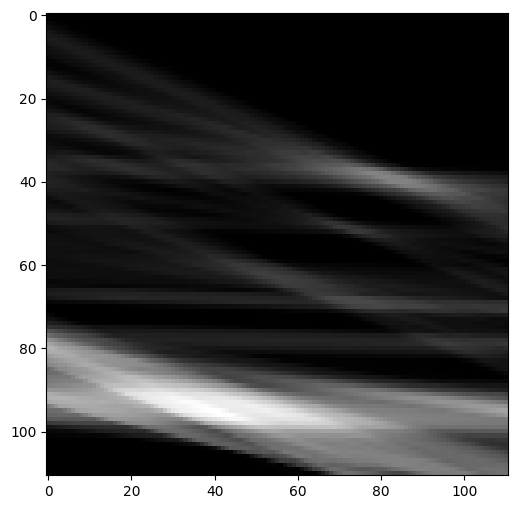

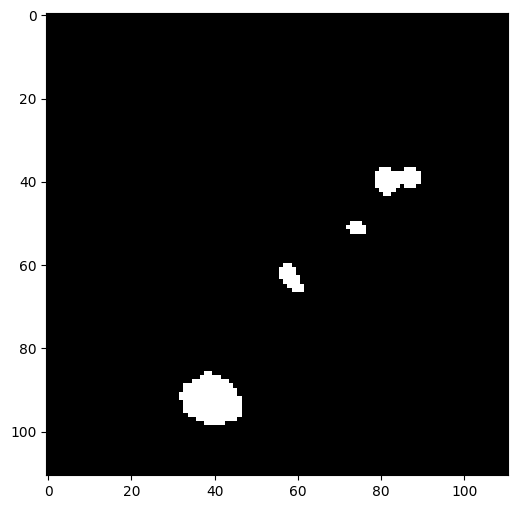

In [80]:
show_slice(test_proj[50])
show_slice(test_gt[50])

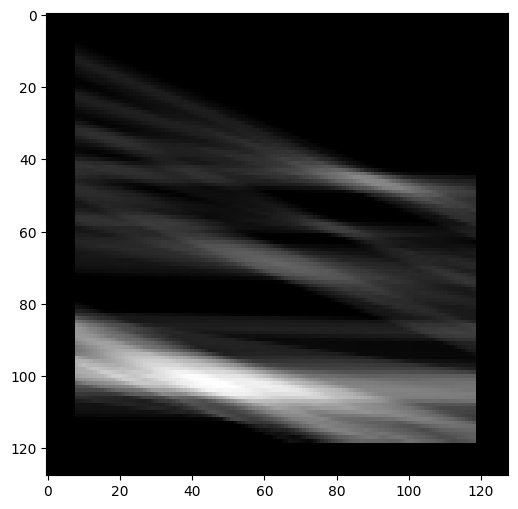

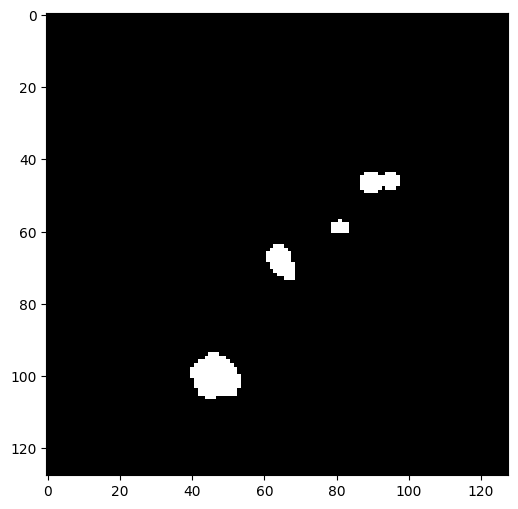

In [83]:
show_slice(pad_test_proj[59])
show_slice(pad_test_gt[59])

In [73]:
np.unique(pad_test_gt)

array([0., 1.], dtype=float32)

In [ ]:
# ## 将数据移动为训练数据和测试数据
# src_data_path = '/data1/liuyang/stent/interior/data/trun_train_data/45_4-fdkNoFilter'
# dest_save_path = '/data1/liuyang/stent/interior/data/trun_test_data/45_4-fdkNoFilter'

# vol_gt_src_data_path = join(src_data_path,'vol_gt')
# vol_train_src_data_path = join(src_data_path,'vol_train')
# vol_gt_dest_save_path = join(dest_save_path,'vol_gt')
# vol_train_dest_save_path = join(dest_save_path,'vol_train')
# os.makedirs(vol_gt_dest_save_path,exist_ok=True)
# os.makedirs(vol_train_dest_save_path,exist_ok=True)

# for i in os.listdir(vol_gt_src_data_path):
#     if(i.startswith('mr_027')):
#         shutil.move(join(vol_gt_src_data_path,i), join(vol_gt_dest_save_path,i))
# for i in os.listdir(vol_train_src_data_path):
#     if(i.startswith('mr_027')):
#         shutil.move(join(vol_train_src_data_path,i), join(vol_train_dest_save_path,i))

In [ ]:
# for root,dirs,files in os.walk('/data1/liuyang/stent/interior/data/trun_train_data'):
#     if(len(files)!=0):
#         print(root,len(files))

#### arrayPadder

In [123]:
## 测试一下padder函数
class ArrayPadder: # 假设这个方法在一个类中
    def pad_to_target_size_diffDimen(
        self,
        input_array, 
        target_size=(128, 128, 128),
        padding_value=0
    ) -> np.ndarray:
        """
        将三维 NumPy 数组填充 (Pad) 到目标尺寸。
        
        策略：
        1. 只填充输入尺寸小于目标尺寸的维度，尽可能居中。
        2. 对于输入尺寸大于或等于目标尺寸的维度，不进行填充，也不抛出异常。
           这意味着最终数组的某些维度可能会大于 target_size。

        Args:
            input_array: 输入的三维数组 (D, H, W)。
            target_size: 目标形状 (D_target, H_target, W_target)。
            padding_value: 用于填充的值 (默认为 0)。

        Returns:
            padded_array: 填充后的数组。其形状取决于输入数组和 target_size。
        """
        # 维度检查保持不变
        if input_array.ndim != 3:
            raise ValueError(f"输入数组必须是三维的，但它的维度是 {input_array.ndim}。")
        if len(target_size) != 3:
             raise ValueError(f"目标尺寸必须是三维的 (D, H, W)，但传入的是 {target_size}。")

        # 1. 初始化填充宽度列表
        pad_width = []
        
        # 2. 计算每个维度的填充量
        for input_dim, target_dim in zip(input_array.shape, target_size):
            
            if input_dim < target_dim:
                # 只有当输入小于目标时，才计算填充量
                
                # 需要填充的总量
                total_padding = target_dim - input_dim
                
                # 计算前部填充量 (尽量居中)
                pad_before = total_padding // 2
                
                # 计算后部填充量 (确保总和正确)
                pad_after = total_padding - pad_before
                
                pad_width.append((pad_before, pad_after))
                
            else: 
                # input_dim >= target_dim
                # 保持该维度不变，填充宽度为零
                pad_width.append((0, 0))

        # 3. 执行 np.pad 填充
        padded_array = np.pad(
            input_array, 
            pad_width=pad_width, 
            mode='constant', 
            constant_values=padding_value
        )
        
        return padded_array
    
    def pad_to_target_size_AllDimen(
        self,
        input_array, 
        target_size = (128, 128, 128),
        padding_value = 0
    ) -> np.ndarray:
        """
        将三维 NumPy 数组填充 (Pad) 到目标尺寸，使用零填充。
        填充策略：在每个轴上尽可能居中。

        Args:
            input_array: 输入的三维数组 (D, H, W)。
            target_size: 目标形状 (D_target, H_target, W_target)。
            padding_value: 用于填充的值 (默认为 0)。

        Returns:
            padded_array: 填充后的数组，形状为 target_size。
        """
        if input_array.ndim != 3:
            raise ValueError(f"输入数组必须是三维的，但它的维度是 {input_array.ndim}。")

        # 1. 初始化填充宽度列表
        pad_width = []
        
        # 2. 计算每个维度的填充量
        for input_dim, target_dim in zip(input_array.shape, target_size):
            if input_dim > target_dim:
                raise ValueError(f"输入尺寸 {input_dim} 大于目标尺寸 {target_dim}，无法填充。")

            # 需要填充的总量
            total_padding = target_dim - input_dim
            
            # 计算前部填充量 (尽量居中)
            pad_before = total_padding // 2
            
            # 计算后部填充量 (确保总和正确)
            pad_after = total_padding - pad_before
            
            pad_width.append((pad_before, pad_after))

        # 3. 执行 np.pad 填充
        # mode='constant' 表示使用一个常数值填充
        padded_array = np.pad(
            input_array, 
            pad_width=pad_width, 
            mode='constant', 
            constant_values=padding_value
        )
        
        return padded_array

In [124]:
padder = ArrayPadder()
test_vol = tiff.imread('/data1/liuyang/stent/interior/data/trun_data/radius-60/test_data/25_5-fdkNoFilter/vol_gt/mr_027_sample_00_0-25.tif')
target_size = (130,128,128)
pad_test_vol = padder.pad_to_target_size_diffDimen(test_vol,target_size=target_size,padding_value=np.min(test_vol))
tiff.imwrite('/data1/liuyang/stent/interior//pad_test_vol.tif',pad_test_vol)

In [126]:
temp_vol_train = tiff.imread('/data1/liuyang/stent/interior/data/trun_data/radius-30/train_data/25_4-fdkNoFilter/vol_train/mr_001_sample_00_0-25.tif')
temp_vol_train.shape


(61, 61, 61)

In [127]:
np.min(temp_vol_train)

0.0

### 测试一下truncate_image_single函数

In [132]:
para_path = '/data1/liuyang/stent/interior/data/voxel_and_dim_info.json'
_,_,_,x_dim,y_dim,z_dim = read_para(para_path)
point = [z_dim//2, x_dim//2, y_dim//2]
image = np.ones([z_dim,x_dim,y_dim],dtype=np.float32)
trun_roi_image = truncate_image_single(image = image, sample_point=point, para_path=para_path, radius = 50, more_radius=4)

In [133]:
trun_roi_image.shape

(109, 109, 109)

### 测试一下get_circle_roi函数

In [137]:
def get_circle_roi(image_shape,roi_center,roi_radius): #获得圆形区域的roi坐标
    Nz, Nx, Ny = image_shape
    center_z, center_x, center_y = roi_center
    z_coords, x_coords, y_coords = np.mgrid[0:Nz, 0:Nx, 0:Ny]
    
    #计算每个体素到圆心在 XY 平面上的距离平方
    distance_sq = (x_coords - center_x)**2 + (y_coords - center_y)**2 + (z_coords - center_z)**2
    radius_sq = roi_radius**2
    mask = distance_sq <= radius_sq

    mask = mask.astype(np.uint8)
    z,x,y = np.where(mask>0)
    # print(mask.shape)
    return np.vstack([z,x,y])

def get_roi_proj(image,geo,angles,valid_mesh):
    # 输入的mesh的shape要是(3,num_of_points)
    roi_image = np.zeros_like(image,np.float32)
    z_coords, x_coords ,y_coords = valid_mesh[0],valid_mesh[1],valid_mesh[2]
    roi_image[z_coords, x_coords, y_coords] = 1 #创建一个只有ROI区域有值的体膜
    roi_mask = tigre.Ax(roi_image,geo,angles)
    proj_data = tigre.Ax(image,geo,angles)
    roi_mask[roi_mask>0.01] = 1 #将其转换为mask
    roi_mask[roi_mask<=0.01] = 0
    roi_proj = proj_data * roi_mask #逐元素相乘提取数据
    return roi_proj,proj_data

In [138]:
point_circle_roi = get_circle_roi([z_dim,x_dim,y_dim], point, 50)

In [139]:
z,x,y = point_circle_roi[0],point_circle_roi[1],point_circle_roi[2]

In [140]:
np.max(x) - np.min(x) + 1

101

### 自动确定阈值——灰度转rgb

In [2]:
import numpy as np

def calculate_percentile_window(data_array):
    """
    计算基于非零元素排序和百分位点设定的 Min/Max 值。

    Max值 = 排序后的非零元素列表中 80% 长度位置的值。
    Min值 = 排序后的非零元素列表中 20% 长度位置的值。

    Args:
        data_array (np.ndarray): 输入的三维体素数据数组。

    Returns:
        tuple: (min_value, max_value)
    """
    
    # 1. 筛选出所有的非零元素
    # flatten() 将数组展平为一维，data_array != 0 返回布尔数组
    non_zero_elements = data_array[data_array != 0]
    
    # 检查非零元素数量
    n = len(non_zero_elements)
    if n == 0:
        print("警告: 图像中没有非零元素，无法计算 Min/Max。返回 (0, 1)。")
        return 0.0, 1.0
    
    # 2. 对非零元素进行排序
    sorted_elements = np.sort(non_zero_elements)

    
    # Min 索引 (20% 位置)
    # np.floor 确保索引不会超出范围，并且通常是保守的选择。
    min_index = int(np.floor(0.1 * n))
    
    # Max 索引 (80% 位置)
    # 我们希望得到 80% 之后的值，所以使用 int(np.ceil(0.80 * n)) - 1 或 int(np.floor(0.80 * n))
    # 为了得到第 80% 处的值 (从 0 开始计数)，使用 np.floor(0.80 * n) 是合理的。
    max_index = int(np.floor(0.9 * n))
    
    # 边界检查：确保索引在有效范围内 [0, n-1]
    if min_index >= n:
        min_index = n - 1
    if max_index >= n:
        max_index = n - 1
        
    # 确保 max_index 至少大于 min_index，除非 n 非常小
    if max_index <= min_index and n > 1:
        max_index = min_index + 1
        if max_index >= n:
             max_index = n - 1
             
    # 4. 获取对应的 Min 和 Max 值
    min_value = sorted_elements[min_index]
    max_value = sorted_elements[max_index]
    
    return min_value, max_value

###  测试一下裁剪函数

In [ ]:
class ArrayCropper:
    def center_crop_to_target_size(
        self,
        input_array, 
        target_size
    ) -> np.ndarray:
        """
        将三维 NumPy 数组中心裁剪 (Center Crop) 到目标尺寸。
        
        策略：
        1. 只对输入尺寸大于目标尺寸的维度进行裁剪。
        2. 如果输入尺寸小于或等于目标尺寸，该维度保持不变（不填充，也不裁剪）。
        3. 裁剪尽可能居中。

        Args:
            input_array: 输入的三维数组 (D, H, W)。
            target_size: 目标形状 (D_target, H_target, W_target)。

        Returns:
            cropped_array: 裁剪后的数组。
        """
        if input_array.ndim != 3:
            raise ValueError(f"输入数组必须是三维的，但它的维度是 {input_array.ndim}。")
        if len(target_size) != 3:
             raise ValueError(f"目标尺寸必须是三维的 (W, D, H)，但传入的是 {target_size}。")

        input_shape = input_array.shape
        crop_slices = [] # 用于 np.ndarray 切片操作的列表

        # 1. 计算每个维度的裁剪范围
        for input_dim, target_dim in zip(input_shape, target_size):
            
            if input_dim > target_dim:
                # --- 需要裁剪 ---
                
                # 需要裁剪的总量
                total_crop = input_dim - target_dim
                
                # 计算前部要跳过的量 (尽量居中)
                # 向下取整，确保裁剪后尺寸正确
                crop_start = total_crop // 2
                
                # 计算裁剪的结束索引
                crop_end = crop_start + target_dim
                
                # 添加切片对象到列表
                crop_slices.append(slice(crop_start, crop_end))
                
            else: 
                # --- 无需裁剪或尺寸不足 ---
                # input_dim <= target_dim
                # 保持该维度不变，切片范围是整个维度
                crop_slices.append(slice(0, input_dim))

        # 2. 执行裁剪切片操作
        # 使用切片列表对数组进行裁剪
        # 将 crop_slices 列表转换为元组，以便用于数组切片
        cropped_array = input_array[tuple(crop_slices)]
        
        return cropped_array

## 检查数据

### 自动确定阈值

In [4]:
def calculate_percentile_window(data_array):
    """
    计算基于非零元素排序和百分位点设定的 Min/Max 值。

    Max值 = 排序后的非零元素列表中 80% 长度位置的值。
    Min值 = 排序后的非零元素列表中 20% 长度位置的值。

    Args:
        data_array (np.ndarray): 输入的三维体素数据数组。

    Returns:
        tuple: (min_value, max_value)
    """
    
    # 1. 筛选出所有的非零元素
    # flatten() 将数组展平为一维，data_array != 0 返回布尔数组
    non_zero_elements = data_array[data_array != 0]
    
    # 检查非零元素数量
    n = len(non_zero_elements)
    if n == 0:
        print("警告: 图像中没有非零元素，无法计算 Min/Max。返回 (0, 1)。")
        return 0.0, 1.0
    
    # 2. 对非零元素进行排序
    sorted_elements = np.sort(non_zero_elements)

    
    # Min 索引 (20% 位置)
    # np.floor 确保索引不会超出范围，并且通常是保守的选择。
    min_index = int(np.floor(0.1 * n))
    
    # Max 索引 (80% 位置)
    # 我们希望得到 80% 之后的值，所以使用 int(np.ceil(0.80 * n)) - 1 或 int(np.floor(0.80 * n))
    # 为了得到第 80% 处的值 (从 0 开始计数)，使用 np.floor(0.80 * n) 是合理的。
    max_index = int(np.floor(0.9 * n))
    
    # 边界检查：确保索引在有效范围内 [0, n-1]
    if min_index >= n:
        min_index = n - 1
    if max_index >= n:
        max_index = n - 1
        
    # 确保 max_index 至少大于 min_index，除非 n 非常小
    if max_index <= min_index and n > 1:
        max_index = min_index + 1
        if max_index >= n:
             max_index = n - 1
             
    # 4. 获取对应的 Min 和 Max 值
    min_value = sorted_elements[min_index]
    max_value = sorted_elements[max_index]
    
    return min_value, max_value

### 检查数据

In [29]:
def merge_images_to_2d_grid(image_obj_list ,  target_cols=5):
    """
    将指定目录下的20张jpg图片合并成一个二维网格图片 (默认为 4x5 网格)。

    Args:
        image_directory (str): 包含图片文件的目录。
        target_cols (int): 网格中的目标列数 (默认为 5)。
        output_filename (str): 输出的合并图片文件名。
    """
    
    num_images = len(image_obj_list)
    first_img = image_obj_list[0]
    single_img_width, single_img_height = first_img.size

    # 计算行数 (确保能容纳所有图片)
    target_rows = (num_images + target_cols - 1) // target_cols

    # 计算最终合并图像的尺寸
    merged_width = single_img_width * target_cols
    merged_height = single_img_height * target_rows

    # 3. 创建新的空白图像
    # 使用 'RGB' 模式，背景色设为白色
    merged_image = Image.new('RGB', (merged_width, merged_height), color='white')

    # 4. 遍历并粘贴图片
    for index, image_file in enumerate(image_obj_list):

        img = image_file.convert('RGB')
        # 确保当前图片尺寸与基准尺寸一致
        if img.size != (single_img_width, single_img_height):
            # 如果尺寸不一致，可以根据需求选择 Resize 或 Skip
            print(f"警告：图片 {index} 尺寸不一致 ({img.size})，已跳过。")
            continue

        # 计算当前图片在网格中的位置 (行和列)
        row = index // target_cols
        col = index % target_cols

        # 计算粘贴的左上角坐标
        x_offset = col * single_img_width
        y_offset = row * single_img_height

        # 粘贴图片
        merged_image.paste(img, (x_offset, y_offset))

    # 5. 保存合并后的图像
    return merged_image

In [42]:
def check_data_single_dir_multi_image(src_path, save_path, index, to_check = None):
    """
    文件结构应该是这样的：
    trun_data/
    ├── radius-30/
    │   ├── test_data/
    │   │   ├── 25_4-fdkNoFilter/
    │   │   │   ├── vol_gt/
    │   │   │   └── vol_train/
    │   │   └── 90_4-fdkNoFilter/
    │   │       ├── vol_gt/
    │   │       └── vol_train/
    │   └── train_data/
    │       ├── 25_4-fdkNoFilter/
    │       │   ├── vol_gt/
    │       │   └── vol_train/
    │       └── 90_4-fdkNoFilter/
    │           ├── vol_gt/
    │           └── vol_train/

    src_path应该是test_data/这一级别
    """
    for j in os.listdir(src_path): #j: 25-4、60-4
        if(to_check is not None):
            if(j not in set(to_down)):
                continue
        vol_path = join(src_path, j)
        # print(vol_path)
        for i in os.listdir(vol_path): # i: vol_gt、vol_train
            vol_train_gt_path = join(vol_path,i)
            save_dir = join(save_path,j,i)
            # print(vol_train_gt_path, save_dir)
            for m in os.listdir(vol_train_gt_path):  # xxx.tif
                proj = tiff.imread(join(vol_train_gt_path,m)) # 读取到的三维图片
                proj_save_path = join(save_dir,m.split('.')[0])
                os.makedirs(proj_save_path,exist_ok=True)
                # 统一窗宽窗位
                min_val, max_val = calculate_percentile_window(proj)
                proj = np.clip(proj,min_val,max_val)
                for k in index:
                    k = int(k)
                    trans_tif_rgb(proj[k]).save(join(proj_save_path,str(k).zfill(2)+'.jpg'))
            print(i)

def check_data_single_dir_single_image(src_path, save_path, index, to_check = None):
    """
    文件结构应该是这样的：
    trun_data/
    ├── radius-30/
    │   ├── test_data/
    │   │   ├── 25_4-fdkNoFilter/
    │   │   │   ├── vol_gt/
    │   │   │   └── vol_train/
    │   │   └── 90_4-fdkNoFilter/
    │   │       ├── vol_gt/
    │   │       └── vol_train/
    │   └── train_data/
    │       ├── 25_4-fdkNoFilter/
    │       │   ├── vol_gt/
    │       │   └── vol_train/
    │       └── 90_4-fdkNoFilter/
    │           ├── vol_gt/
    │           └── vol_train/

    src_path应该是test_data/这一级别
    """
    for j in os.listdir(src_path): #j: 25-4、60-4
        if(to_check is not None):
            if(j not in set(to_check)):
                continue
        print(j)
        vol_path = join(src_path, j)
        for i in os.listdir(vol_path): # i: vol_gt、vol_train
            vol_train_gt_path = join(vol_path,i)
            save_dir = join(save_path,j,i)
            os.makedirs(save_dir,exist_ok=True)
            for m in os.listdir(vol_train_gt_path):  # xxx.tif
                proj = tiff.imread(join(vol_train_gt_path,m)) # 读取到的三维图片
                # 统一窗宽窗位
                if(m=='vol_train'):
                    min_val, max_val = calculate_percentile_window(proj)
                    proj = np.clip(proj,min_val,max_val)
                jpg_files = []
                for k in index:
                    k = int(k)
                    jpg_files.append(trans_tif_rgb(proj[k]))
                merge_images_to_2d_grid(jpg_files,target_cols=5).save(join(save_dir,m.split('.')[0]+'.jpg'))
            print(i)

def check_data_single_radius(radius_path, save_path, index, to_check = None):
    """
    文件结构应该是这样的：
    trun_data/
    ├── radius-30/
    │   ├── test_data/
    │   │   ├── 25_4-fdkNoFilter/
    │   │   │   ├── vol_gt/
    │   │   │   └── vol_train/
    │   │   └── 90_4-fdkNoFilter/
    │   │       ├── vol_gt/
    │   │       └── vol_train/
    │   └── train_data/
    │       ├── 25_4-fdkNoFilter/
    │       │   ├── vol_gt/
    │       │   └── vol_train/
    │       └── 90_4-fdkNoFilter/
    │           ├── vol_gt/
    │           └── vol_train/

    src_path应该是radius-30/这一级别
    """
    for h in os.listdir(radius_path):
        src_path = join(radius_path,h)
        for j in os.listdir(src_path): #j: 25-4、60-4
            if(to_check is not None):
                if(j not in set(to_down)):
                    continue
            vol_path = join(src_path, j)
            for i in os.listdir(vol_path): # i: vol_gt、vol_train
                vol_train_gt_path = join(vol_path,i)
                save_dir = join(save_path,h,j,i)
                print(save_dir)
                for m in os.listdir(vol_train_gt_path):  # xxx.tif
                    proj = tiff.imread(join(vol_train_gt_path,m)) # 读取到的三维图片
                    proj_save_path = join(save_dir,m.split('.')[0])
                    os.makedirs(proj_save_path,exist_ok=True)
                    # 统一窗宽窗位
                    min_val, max_val = calculate_percentile_window(proj)
                    proj = np.clip(proj,min_val,max_val)
                    for k in index:
                        k = int(k)
                        trans_tif_rgb(proj[k]).save(join(proj_save_path,str(k).zfill(2)+'.jpg'))
            print(j)

In [48]:
# radius_path = '/data1/liuyang/stent/interior/data/trun_data/radius-60'
# save_path = '/data1/liuyang/stent/interior/data/save_to_check/radius-60'
radius_path = '/data1/liuyang/stent/interior/data/trun_data/radius-60/train_data'
save_path = '/data1/liuyang/stent/interior/data/save_to_check/radius-60'
to_down  = ['180_180-fdkNoFilter']
# index = np.linspace(0,129,20,endpoint=False)
index = np.linspace(0,121,20,endpoint=False)

# check_data_single_radius(radius_path=radius_path, save_path=save_path, index=index)
check_data_single_dir_single_image(src_path=radius_path, save_path=save_path, index=index, to_check=to_down)



180_180-fdkNoFilter
vol_train
vol_gt


In [ ]:

# ## 将抽离的图片合并为同一张二维图片

# img_path = '/data1/liuyang/stent/interior/data/save_to_check/radius-60/25_4-fdkNoFilter/vol_train/mr_027_sample_09_150-175'
# files = [Image.open(join(img_path,i)) for i in sorted(os.listdir(img_path))]
# merge_image = merge_images_to_2d_grid(files)
# merge_image.save('/data1/liuyang/stent/interior/data/save_to_check//merge_test.jpg')

In [183]:
test_proj = tiff.imread('/data1/liuyang/stent/interior/data/trun_data/radius-60/test_data/25_4-fdkNoFilter/vol_train/mr_027_sample_00_0-25.tif')
print(np.min(test_proj),np.max(test_proj))

min_val_1, max_val_1 = calculate_percentile_window(test_proj)
# min_val, max_val = np.min(test_proj), np.max(test_proj)
# min_val_1 = 0.2 * (max_val - min_val)
# max_val_1 = 0.8 * (max_val - min_val)

test_proj = np.clip(test_proj,min_val_1,max_val_1)
print(np.min(test_proj),np.max(test_proj))
# for k in index:
#     k = int(k)
#     trans_tif_rgb(proj[k]).save(join(proj_save_path,str(k).zfill(2)+'.jpg'))

0.0 58.50235
1.2132604 11.893605


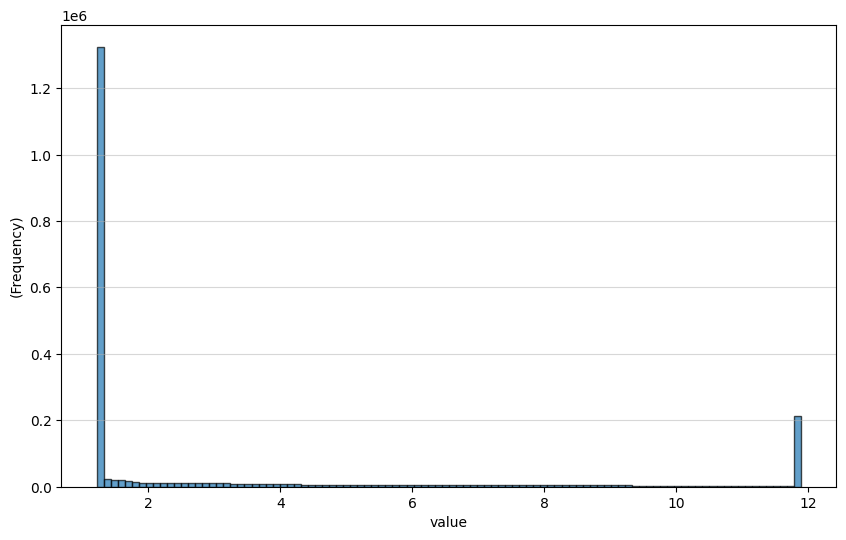

In [184]:
# 3. 绘制非零元素的直方图分布
# test_proj = tiff.imread('/data1/liuyang/stent/interior/data/trun_data/radius-60/test_data/25_4-fdkNoFilter/vol_train/mr_027_sample_00_0-25.tif')
non_zero_elements = test_proj[test_proj != 0]
bins = 100 # 定义直方图的条数

plt.figure(figsize=(10, 6))
# 绘制直方图
plt.hist(non_zero_elements, bins=bins, edgecolor='black', alpha=0.7)

# plt.title('三维 Ndarray 中非零元素的直方图分布')
plt.xlabel('value')
plt.ylabel('(Frequency)')
plt.grid(axis='y', alpha=0.5)

# 保存图像
plt.savefig('non_zero_histogram.png')
plt.show() # 在实际环境中，如果不是在 Jupyter/Colab 中，可能需要这行来显示图像


In [4]:
tar_dir = '/data1/liuyang/stent/interior/data/other/smile/helper/train_data/voxel_0.2/skeleton'
for i in os.listdir(tar_dir):
  nib.save(nib.load(join(tar_dir, i)), join(tar_dir, i.split('.')[0]+'.nii.gz'))
  os.remove(join(tar_dir, i))

In [ ]:
# helper_path='/data1/liuyang/stent/interior/data/other/smile/root_data'
# for root, dirs, files in os.walk(helper_path):
#   for i in files:
#     if(i.endswith('.nii')):
#       # nib_i = nib.load(join(root, i))
#       # nib.save(nib_i, join(root,i+'.gz'))
#       os.remove(join(root, i))


In [15]:
nib.load('/data1/liuyang/stent/nnUNet/data/nnUNet_raw/Dataset368_costa-radius64-60-4/imagesTr/ICBM-010-sample-00-0-60_0000.nii.gz').header.get_zooms()

(0.5, 0.5, 0.8)

In [ ]:
proj_path = '/data1/liuyang/stent/interior/data/corr_data/data/costa/voxel_0.2/src_data/radius-64/corr_stent/test_data/proj_gt'
save_path = '/data1/liuyang/stent/interior/data/corr_data/data/costa/voxel_0.2/src_data/radius-64/corr_stent/test_data/proj_gt_111'
for i in os.listdir(proj_path):
  if(i.endswith('.nii.gz')):
    # shutil.movetree(join(proj_path, i), join(save_path, i))
    shutil.move(join(proj_path, i), join(save_path, i))

## 检查一下trun_three_data

In [32]:
# gt_nib = nib.load('/data1/liuyang/stent/interior/data/corr_data/data/costa/voxel_0.2/trun_data_three/radius-64/corr_vessel/train_data/60_3-fdkYesFilter/vol_gt/ICBM_010_sample_00_0-60.nii.gz')
# train_nib = nib.load('/data1/liuyang/stent/interior/data/corr_data/data/costa/voxel_0.2/trun_data_three/radius-64/corr_vessel/train_data/60_3-fdkYesFilter/vol_train_no_masked/ICBM_010_sample_00_0-60.nii.gz')
# train_nib = nib.load('/data1/liuyang/stent/interior/data/corr_data/data/costa/voxel_0.2/trun_data_three/radius-64/corr_vessel/train_data/60_3-fdkYesFilter/vol_train_no_masked/ICBM_010_sample_01_60-120.nii.gz')
train_nib = nib.load('/data1/liuyang/stent/interior/data/corr_data/data/costa/voxel_0.2/trun_data_three/radius-64/corr_stent/train_data/60_3-fdkNoFilter/vol_train_no_masked/ICBM_010_sample_00_60-120.nii.gz')





In [6]:
gt_nib.shape

(128, 128, 128)

In [7]:
train_nib.shape

(128, 128, 128, 3)

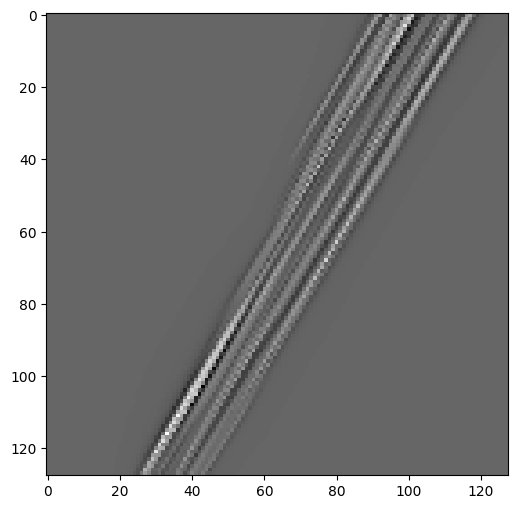

In [35]:
show_slice(train_nib.get_fdata()[:,:,70,2])

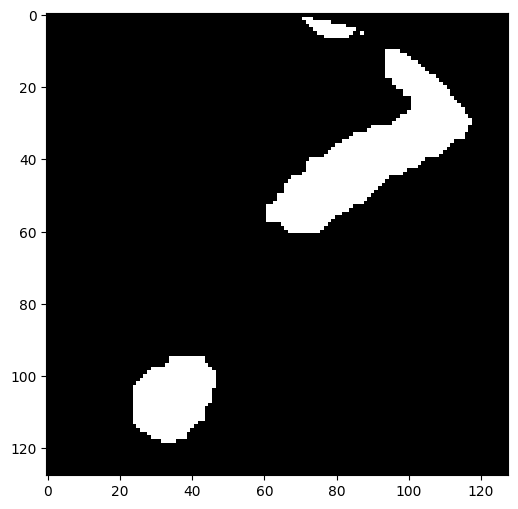

In [15]:
show_slice(gt_nib.get_fdata()[:,:,70])

### 其它

In [7]:
src_path = '/data1/liuyang/stent/interior/data/corr_data/data/costa_test_2/voxel_0.2/trun_data/radius-64/corr_stent/train_data/90_2-fdkNoFilter'
# for i in os.listdir(join(src_path, "vol_gt_no_masked")):
#     i_r = i.replace('_','-').split('.nii.gz')[0]+'_0000.nii.gz'
#     os.rename(join(src_path, "vol_gt_no_masked", i), join(src_path, "vol_gt_no_masked", i_r))

for i in os.listdir(join(src_path, "vol_gt_no_masked")):
    i_r = i.split('_0000.nii.gz')[0]+'.nii.gz'
    os.rename(join(src_path, "vol_gt_no_masked", i), join(src_path, "vol_gt_no_masked", i_r))